# Previsão do PIB Trimestral Brasileiro com Modelos SARIMA (Metodologia Box-Jenkins)

**Pipeline Econométrico de Séries Temporais | Dados Oficiais via API SIDRA/IBGE (1996–2024)**

Este projeto aplica a metodologia clássica de **Box-Jenkins** para identificar, estimar, diagnosticar e validar um modelo univariado **SARIMA** aplicado ao Produto Interno Bruto (PIB) Trimestral brasileiro a preços correntes (Tabela 1846 do IBGE).

### Estrutura da Análise
1. **Contexto Macroeconômico e Estratégia de Modelagem**
2. **Ingestão Automatizada via API SIDRA/IBGE** (com *fallback* local para reprodutibilidade offline)
3. **Análise Exploratória (EDA) e Decomposição Sazonal Trimestral**
4. **Testes Formais de Estacionariedade e Raiz Unitária** (`ADF`, `Phillips-Perron` e `KPSS`)
5. **Identificação Box-Jenkins** (Correlogramas `FAC`/`FACP` e busca em grade via `AIC`/`BIC`/`HQIC`)
6. **Estimação e Diagnóstico Completo de Resíduos** (`Ljung-Box`, `Jarque-Bera`, `ARCH-LM` e `Goldfeld-Quandt`)
7. **Validação Out-of-Sample (2022)**: Previsão Dinâmica vs. Estática vs. *Benchmarks* (`Naive Sazonal` e `Holt-Winters`)
8. **Projeção Pós-Estudo (2023–2024) e Backtest de Mundo Real vs. IBGE**
9. **Conclusão Executiva, Limitações e Próximos Passos**

## 1. Introdução e Contexto Macroeconômico

O Produto Interno Bruto (**PIB**) sintetiza o valor agregado de bens e serviços finais produzidos na economia em determinado período, servindo como termômetro central para decisões de política monetária, planejamento fiscal e alocação de capital.

Em séries macroeconômicas de alta inércia e forte sazonalidade intra-anual, modelos autorregressivos integrados de médias móveis sazonais — **$\text{SARIMA}(p, d, q)(P, D, Q)_s$** — fornecem um *benchmark* estatístico transparente e rigoroso a partir da própria trajetória histórica da variável:

$$\Phi_P(L^s)\,\phi_p(L)\,(1 - L)^d\,(1 - L^s)^D\, y_t = \Theta_Q(L^s)\,\theta_q(L)\,\varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \sigma^2)$$

### Decisões Fundamentais de Desenho
- **Transformação Logarítmica ($y_t = \log(\text{PIB}_t)$):** O PIB nominal brasileiro cresce de forma aproximadamente exponencial ao longo de quase três décadas (de R\$ 189,3 bi no 1º tri/1996 para R\$ 2,64 tri no 4º tri/2022). O logaritmo natural estabiliza a variância proporcional e transforma diferenças de primeira ordem em aproximações diretas das taxas de crescimento ($\Delta \log Y_t \approx g_t$).
- **Frequência Trimestral ($s = 4$):** A sazonalidade econômica no Brasil segue o calendário trimestral (efeito de safras no 1º/2º trimestres e aquecimento de varejo/13º salário no 4º trimestre), exigindo periodicidade sazonal $s=4$.
- **Separação Temporal Estrita (Sem Vazamento de Dados):**
  - **Treino (Identificação e Estimação):** `1996-T1` a `2021-T4` (104 trimestres).
  - **Teste / Validação Out-of-Sample:** `2022-T1` a `2022-T4` (4 trimestres), contrastando previsões **Dinâmica** (*multi-step*) e **Estática** (*one-step-ahead*) contra *benchmarks* clássicos.
  - **Projeção e Backtest Pós-Estudo:** Modelo reestimado em `1996-T1`–`2022-T4` (108 trimestres) para projetar `2023-T1` a `2024-T4` (8 trimestres) e confrontar as projeções com os números efetivamente divulgados pelo IBGE.

### 1.1 Configuração do Ambiente e Funções Auxiliares

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
)
from statsmodels.graphics.gofplots import qqplot
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch, het_goldfeldquandt
from statsmodels.stats.stattools import jarque_bera
from statsmodels.tsa.adfvalues import mackinnoncrit, mackinnonp
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import acf, adfuller, kpss, pacf

warnings.filterwarnings("ignore", category=FutureWarning, message=".*currently returns a plain tuple.*")

# Diretório para exportação de figuras
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

# Paleta editorial e estilo consistente
PALETTE = {
    "navy": "#1B365D",
    "teal": "#008080",
    "coral": "#D95F02",
    "gold": "#D97706",
    "purple": "#6B46C1",
    "slate": "#4A5568",
    "muted": "#94A3B8",
    "bg": "#FFFFFF",
    "grid": "#E2E8F0",
}

plt.rcParams.update({
    "figure.facecolor": PALETTE["bg"],
    "axes.facecolor": PALETTE["bg"],
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 0.9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": PALETTE["grid"],
    "grid.linestyle": "--",
    "grid.linewidth": 0.7,
    "grid.alpha": 0.8,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Segoe UI"],
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "legend.frameon": True,
    "legend.facecolor": "#FFFFFF",
    "legend.edgecolor": "#E2E8F0",
})


def formatar_trimestre(dt_index: pd.DatetimeIndex) -> list[str]:
    '''Converte um DatetimeIndex trimestral para rótulos no padrão YYYY-TQ.'''
    return [f"{d.year}-T{(d.month - 1) // 3 + 1}" for d in dt_index]


def formatar_brl_eixo(valor_milhoes: float, _pos: int | None = None) -> str:
    '''Formata valores em R$ milhões para R$ bi/tri em eixos de gráficos.'''
    if abs(valor_milhoes) >= 1_000_000:
        return f"R$ {valor_milhoes / 1_000_000:.1f} tri"
    return f"R$ {valor_milhoes / 1_000:.0f} bi"


def calcular_metricas(y_real: pd.Series, y_pred: pd.Series) -> dict[str, float]:
    '''Calcula RMSE, MAE e MAPE (%) na escala original da série.'''
    return {
        "RMSE (R$ mi)": float(np.sqrt(mean_squared_error(y_real, y_pred))),
        "MAE (R$ mi)": float(mean_absolute_error(y_real, y_pred)),
        "MAPE (%)": float(mean_absolute_percentage_error(y_real, y_pred) * 100),
    }


def salvar_figura(fig: plt.Figure, filename: str) -> Path:
    '''Salva figura em alta resolução (300 DPI) no diretório figures/.'''
    path = FIGURES_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight", facecolor=fig.get_facecolor())
    return path

## 2. Ingestão de Dados via API SIDRA/IBGE (com Fallback Local)

A série histórica é obtida diretamente da **API SIDRA do IBGE**:
- **Tabela `1846`**: *Contas Nacionais Trimestrais — Valores a preços correntes*
- **Variável `585`**: *Valores a preços correntes (Milhões de Reais)*
- **Classificação `c11255/90707`**: *PIB a preços de mercado*

Caso não haja conectividade de rede no momento da execução, o *loader* aciona automaticamente o arquivo local `serie_historica_pib.xlsx` (extração original de 1996-T1 a 2022-T4) para preservar a reprodutibilidade do estudo principal.

In [2]:
SIDRA_URL = (
    "https://apisidra.ibge.gov.br/values/t/1846/n1/all/v/585/p/all/c11255/90707?formato=json"
)
EXCEL_FALLBACK = Path("serie_historica_pib.xlsx")


def carregar_pib_ibge(
    url: str = SIDRA_URL,
    fallback_path: Path = EXCEL_FALLBACK,
    timeout: int = 20,
) -> tuple[pd.DataFrame, str]:
    '''Busca o PIB trimestral nominal na API SIDRA/IBGE com fallback para Excel local.'''
    try:
        resp = requests.get(url, timeout=timeout)
        resp.raise_for_status()
        registros = resp.json()[1:]  # O primeiro elemento contém os metadados do cabeçalho
        dados = []
        for item in registros:
            codigo_tri = item.get("D3C", "")
            valor_str = item.get("V", "")
            if len(codigo_tri) == 6 and valor_str not in ("", "-", "..."):
                dados.append({"periodo": codigo_tri, "PIB": float(valor_str)})
        df_api = pd.DataFrame(dados)
        periodos = pd.PeriodIndex(
            df_api["periodo"].str[:4] + "Q" + df_api["periodo"].str[4:].astype(int).astype(str),
            freq="Q",
        )
        df_api["date"] = periodos.to_timestamp(how="end").normalize()
        df_api = df_api.set_index("date")[["PIB"]].sort_index()
        df_api.index.freq = "QE-DEC"
        return df_api, "API SIDRA/IBGE (ao vivo)"
    except Exception as exc:
        if not fallback_path.exists():
            raise RuntimeError(
                f"Falha na API SIDRA ({exc}) e arquivo fallback '{fallback_path}' não encontrado."
            ) from exc
        df_xl = pd.read_excel(fallback_path).dropna().copy()
        df_xl["date"] = pd.date_range(start="1996-01-01", periods=len(df_xl), freq="QE-DEC")
        df_xl = df_xl.set_index("date")[["PIB"]].astype(float)
        df_xl.index.freq = "QE-DEC"
        return df_xl, f"Fallback local ({fallback_path.name})"


df_completo, fonte_dados = carregar_pib_ibge()

# Recorte temporal do estudo (1996-T1 a 2022-T4) e retenção de 2023-2024 para backtest real
df_estudo = df_completo.loc["1996-01-01":"2022-12-31"].copy()
df_pos_estudo = df_completo.loc["2023-01-01":"2024-12-31"].copy()

train = df_estudo.loc[:"2021-12-31", "PIB"]
test = df_estudo.loc["2022-01-01":"2022-12-31", "PIB"]
study_series = df_estudo["PIB"]

log_train = np.log(train)
log_test = np.log(test)
log_study = np.log(study_series)

# Comparação rápida com a extração estática original (maio/2023)
df_xl_ref = pd.read_excel(EXCEL_FALLBACK).dropna().copy()
df_xl_ref["date"] = pd.date_range(start="1996-01-01", periods=len(df_xl_ref), freq="QE-DEC")
df_xl_ref = df_xl_ref.set_index("date")[["PIB"]].astype(float)
comp_revisao = df_estudo.join(df_xl_ref, lsuffix="_API", rsuffix="_Excel")
comp_revisao["Dif_abs"] = comp_revisao["PIB_API"] - comp_revisao["PIB_Excel"]
n_revisados = int((comp_revisao["Dif_abs"] != 0).sum())

resumo_ingestao = pd.DataFrame([
    {
        "Partição": "Treino (Estimação)",
        "Início": formatar_trimestre(train.index)[0],
        "Fim": formatar_trimestre(train.index)[-1],
        "Trimestres": len(train),
        "PIB Mín (R$ mi)": f"{train.min():,.0f}",
        "PIB Máx (R$ mi)": f"{train.max():,.0f}",
    },
    {
        "Partição": "Teste (Validação 2022)",
        "Início": formatar_trimestre(test.index)[0],
        "Fim": formatar_trimestre(test.index)[-1],
        "Trimestres": len(test),
        "PIB Mín (R$ mi)": f"{test.min():,.0f}",
        "PIB Máx (R$ mi)": f"{test.max():,.0f}",
    },
    {
        "Partição": "Backtest Pós-Estudo (2023–2024)",
        "Início": formatar_trimestre(df_pos_estudo.index)[0] if len(df_pos_estudo) else "-",
        "Fim": formatar_trimestre(df_pos_estudo.index)[-1] if len(df_pos_estudo) else "-",
        "Trimestres": len(df_pos_estudo),
        "PIB Mín (R$ mi)": f"{df_pos_estudo['PIB'].min():,.0f}" if len(df_pos_estudo) else "-",
        "PIB Máx (R$ mi)": f"{df_pos_estudo['PIB'].max():,.0f}" if len(df_pos_estudo) else "-",
    },
])

print(f"Fonte ativa: {fonte_dados}")
print(f"Total disponível na API: {len(df_completo)} trimestres | Trimestres revisados vs. planilha de mai/2023: {n_revisados}")
display(resumo_ingestao)

Fonte ativa: API SIDRA/IBGE (ao vivo)
Total disponível na API: 122 trimestres | Trimestres revisados vs. planilha de mai/2023: 37


,Partição,Início,Fim,Trimestres,PIB Mín (R$ mi),PIB Máx (R$ mi)
0,Treino (Estimação),1996-T1,2021-T4,104,"189,323","2,355,982"
1,Teste (Validação 2022),2022-T1,2022-T4,4,"2,319,528","2,641,485"
2,Backtest Pós-Estudo (2023–2024),2023-T1,2024-T4,8,"2,581,018","3,063,723"


> **Nota Técnica — Revisões Oficiais do Sistema de Contas Nacionais (IBGE):**
> Ao consultar a API SIDRA ao vivo, observa-se que o IBGE promoveu revisões metodológicas e contábeis na série histórica em relação à extração estática original de maio/2023 (`serie_historica_pib.xlsx`), especialmente nos anos de 2021 e 2022 (por exemplo, o PIB do 4º trimestre de 2022 foi revisado de R\$ 2.584.126 milhões para R\$ 2.641.485 milhões). A utilização da API garante alinhamento integral com os números oficiais vigentes.

## 3. Análise Exploratória da Série Temporal (EDA)

Nesta etapa investigamos a dinâmica estrutural do PIB nominal entre 1996 e 2022:
- **Tendência de longo prazo e variância crescente:** O crescimento nominal composto (atividade real + deflator implícito/inflação) produz oscilações em Reais cada vez mais amplas ao longo do tempo.
- **Choques macroeconômicos:** Quedas abruptas ou desacelerações visíveis na Crise Financeira Global (2008–2009), na recessão doméstica (2015–2016) e no choque agudo da pandemia de COVID-19 (2020-T2).
- **Sazonalidade intra-anual:** Padrão recorrente entre os quatro trimestres do ano, o que fundamenta o uso da periodicidade sazonal $s = 4$.

,Métrica,Valor
0,Observações (1996-T1 a 2022-T4),108 trimestres
1,Média do PIB Trimestral (R$ milhões),"R$ 1,013,447"
2,Mediana (R$ milhões),"R$ 834,232"
3,Desvio-Padrão (R$ milhões),"R$ 674,005"
4,CAGR Nominal Anualizado (1996–2022),10.35% a.a.
5,Crescimento YoY Médio no Treino (1997–2021),9.99% a.a.
6,Crescimento YoY Médio no Teste (2022),11.80% a.a.
7,Maior Contração Trimestral QoQ (Pandemia 2020-T2),-6.18%


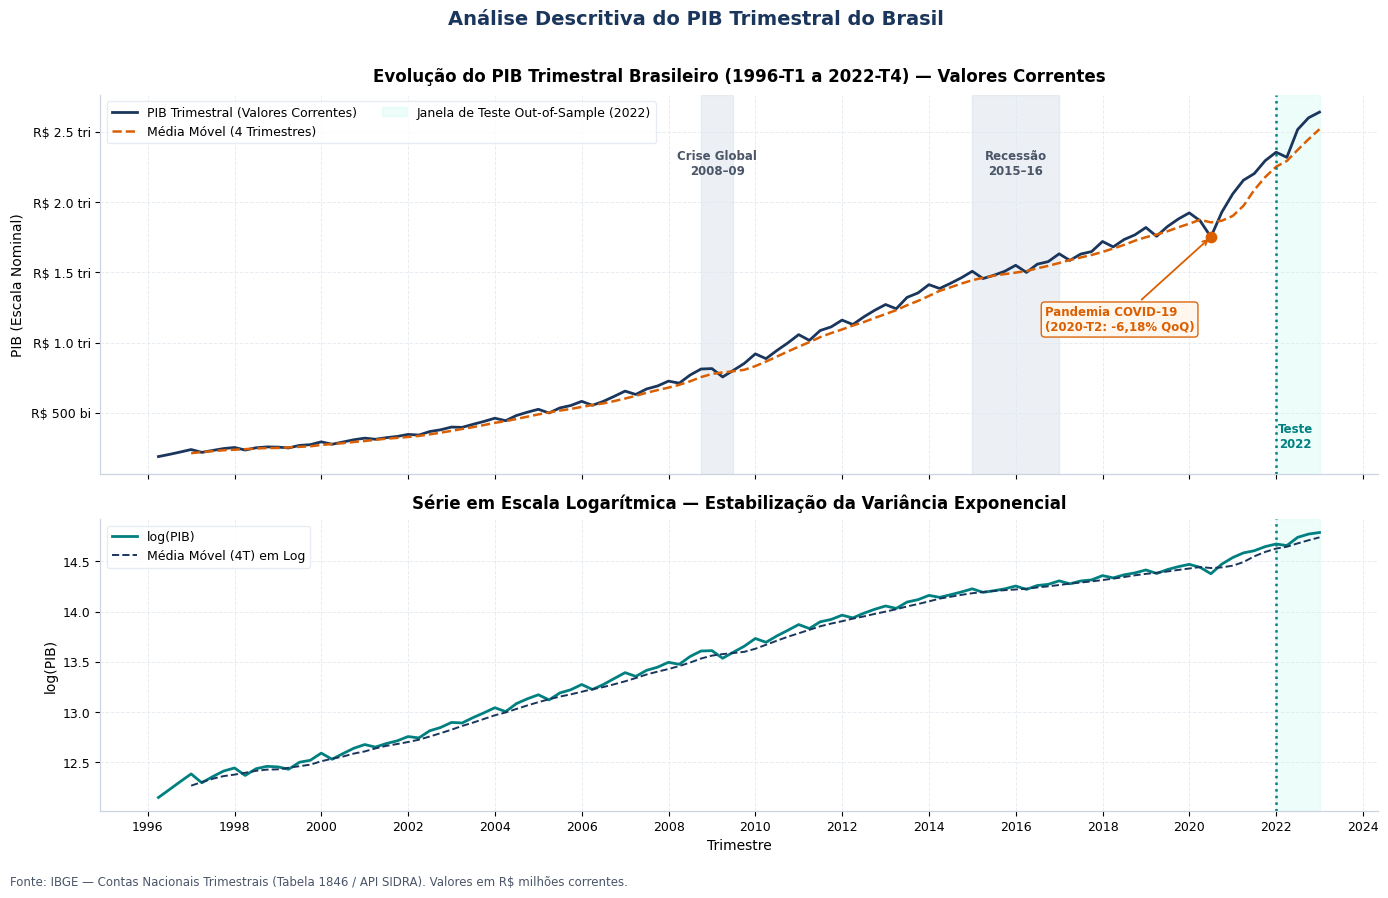

In [3]:
# Estatísticas descritivas do estudo (1996-2022) e taxa de crescimento
cresc_yoy_treino = (train / train.shift(4) - 1).dropna() * 100
cresc_yoy_teste = ((df_estudo["PIB"] / df_estudo["PIB"].shift(4) - 1).loc[test.index]) * 100
cagr_nominal = ((study_series.iloc[-1] / study_series.iloc[0]) ** (4 / (len(study_series) - 1)) - 1) * 100

estatisticas_eda = pd.DataFrame({
    "Métrica": [
        "Observações (1996-T1 a 2022-T4)",
        "Média do PIB Trimestral (R$ milhões)",
        "Mediana (R$ milhões)",
        "Desvio-Padrão (R$ milhões)",
        "CAGR Nominal Anualizado (1996–2022)",
        "Crescimento YoY Médio no Treino (1997–2021)",
        "Crescimento YoY Médio no Teste (2022)",
        "Maior Contração Trimestral QoQ (Pandemia 2020-T2)",
    ],
    "Valor": [
        f"{len(study_series)} trimestres",
        f"R$ {study_series.mean():,.0f}",
        f"R$ {study_series.median():,.0f}",
        f"R$ {study_series.std():,.0f}",
        f"{cagr_nominal:.2f}% a.a.",
        f"{cresc_yoy_treino.mean():.2f}% a.a.",
        f"{cresc_yoy_teste.mean():.2f}% a.a.",
        f"{(study_series.pct_change().loc['2020-06-30'] * 100):.2f}%",
    ],
})
display(estatisticas_eda)

# Gráfico 1: Série Histórica em Nível e em Log
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.3, 1.0]})

ma_4t = study_series.rolling(window=4).mean()
ax1.plot(study_series.index, study_series.values, color=PALETTE["navy"], lw=2.0, label="PIB Trimestral (Valores Correntes)")
ax1.plot(ma_4t.index, ma_4t.values, color=PALETTE["coral"], lw=1.8, linestyle="--", label="Média Móvel (4 Trimestres)")

# Marcos macroeconômicos
eventos = [
    ("2008-09-30", "2009-06-30", "Crise Global\n2008–09", 0.90),
    ("2015-01-01", "2016-12-31", "Recessão\n2015–16", 0.90),
]
for ini, fim, rotulo, ypos in eventos:
    ax1.axvspan(pd.Timestamp(ini), pd.Timestamp(fim), color="#CBD5E1", alpha=0.35, zorder=0)
    meio = pd.Timestamp(ini) + (pd.Timestamp(fim) - pd.Timestamp(ini)) / 2
    ax1.text(meio, study_series.max() * ypos, rotulo, ha="center", va="top", fontsize=8.5, color=PALETTE["slate"], fontweight="bold")

# Anotação Pandemia COVID-19 (2020-T2) posicionada abaixo da curva para evitar sobreposição
covid_dt = pd.Timestamp("2020-06-30")
covid_val = study_series.loc[covid_dt]
ax1.scatter([covid_dt], [covid_val], color=PALETTE["coral"], s=55, zorder=5)
ax1.annotate(
    "Pandemia COVID-19\n(2020-T2: -6,18% QoQ)",
    xy=(covid_dt, covid_val),
    xytext=(pd.Timestamp("2016-09-01"), covid_val * 0.62),
    arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.3),
    fontsize=8.5,
    fontweight="bold",
    color=PALETTE["coral"],
    bbox=dict(boxstyle="round,pad=0.3", fc="#FFF7ED", ec=PALETTE["coral"], alpha=0.95),
)

# Divisão Treino / Teste
split_dt = pd.Timestamp("2021-12-31")
for ax in (ax1, ax2):
    ax.axvline(split_dt, color=PALETTE["teal"], linestyle=":", lw=1.8)
ax1.axvspan(split_dt, study_series.index[-1], color="#CCFBF1", alpha=0.35, zorder=0, label="Janela de Teste Out-of-Sample (2022)")
ax1.text(pd.Timestamp("2022-06-15"), study_series.min() * 1.35, "Teste\n2022", ha="center", fontsize=8.5, color=PALETTE["teal"], fontweight="bold")

ax1.yaxis.set_major_formatter(mticker.FuncFormatter(formatar_brl_eixo))
ax1.set_ylabel("PIB (Escala Nominal)")
ax1.set_title("Evolução do PIB Trimestral Brasileiro (1996-T1 a 2022-T4) — Valores Correntes", pad=10)
ax1.legend(loc="upper left", ncol=2)

# Painel Inferior: Escala Logarítmica
ax2.plot(log_study.index, log_study.values, color=PALETTE["teal"], lw=2.0, label="log(PIB)")
ax2.plot(log_study.index, log_study.rolling(4).mean(), color=PALETTE["navy"], lw=1.4, linestyle="--", label="Média Móvel (4T) em Log")
ax2.axvspan(split_dt, study_series.index[-1], color="#CCFBF1", alpha=0.35, zorder=0)
ax2.set_ylabel("log(PIB)")
ax2.set_xlabel("Trimestre")
ax2.set_title("Série em Escala Logarítmica — Estabilização da Variância Exponencial", pad=8)
ax2.legend(loc="upper left")
ax2.xaxis.set_major_locator(mdates.YearLocator(2))
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle("Análise Descritiva do PIB Trimestral do Brasil", fontsize=14, fontweight="bold", y=1.01, color=PALETTE["navy"])
fig.text(0.01, -0.02, "Fonte: IBGE — Contas Nacionais Trimestrais (Tabela 1846 / API SIDRA). Valores em R$ milhões correntes.", fontsize=8.5, color=PALETTE["slate"])
plt.tight_layout()
salvar_figura(fig, "01_serie_historica_pib.png")
plt.show()

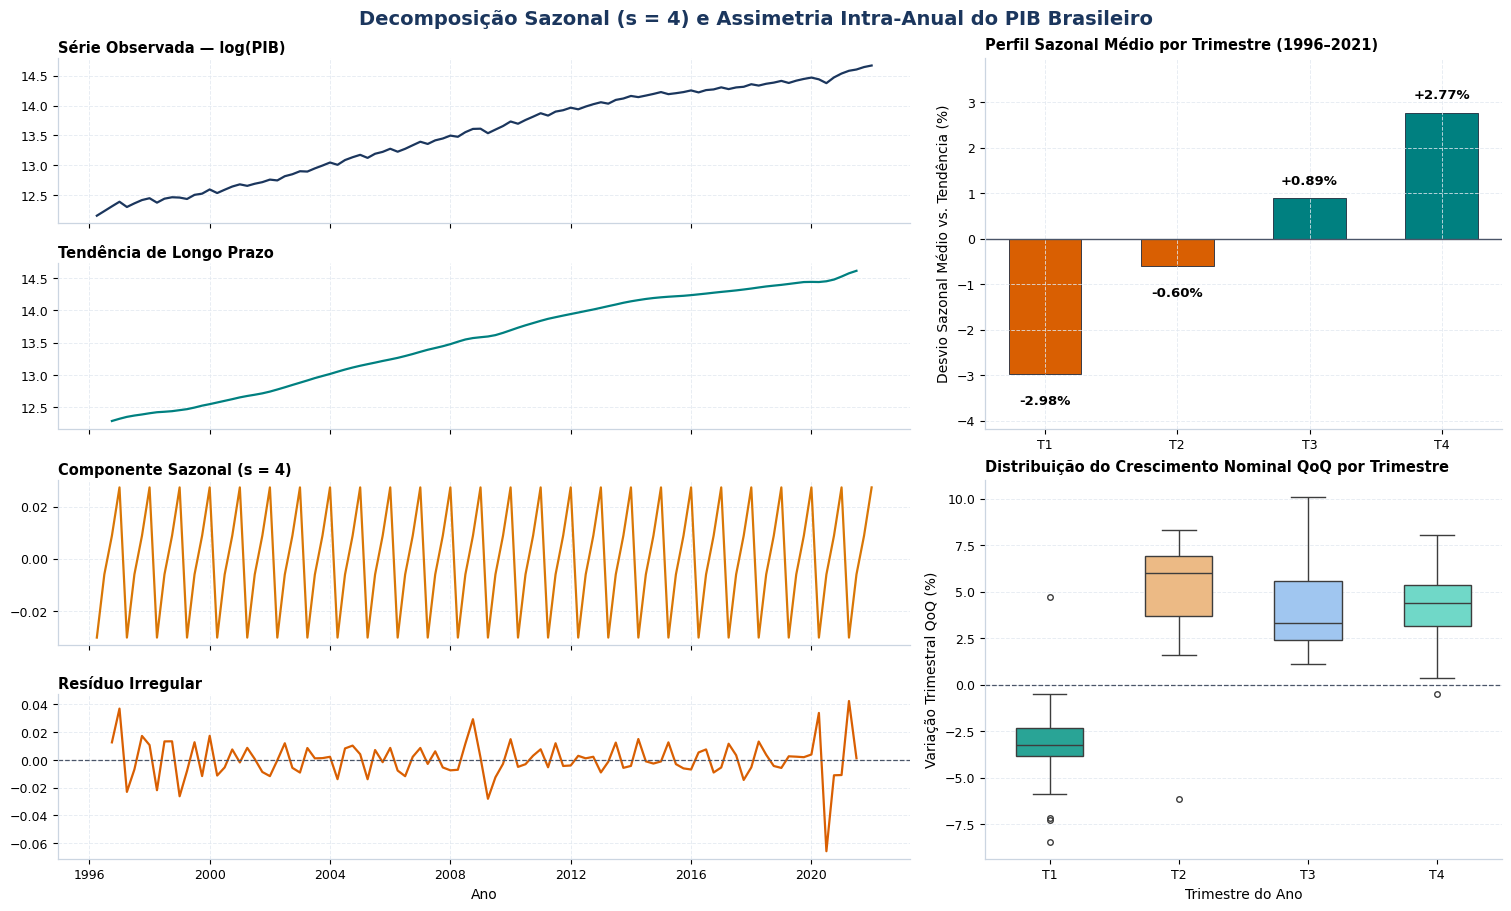

In [4]:
# Gráfico 2: Decomposição Sazonal (period=4) e Perfil Sazonal por Trimestre
decomp = seasonal_decompose(log_train, model="additive", period=4)

fig = plt.figure(figsize=(15, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1.65, 1.0], height_ratios=[1, 1, 1, 1])

componentes = [
    (decomp.observed, "Série Observada — log(PIB)", PALETTE["navy"]),
    (decomp.trend, "Tendência de Longo Prazo", PALETTE["teal"]),
    (decomp.seasonal, "Componente Sazonal (s = 4)", PALETTE["gold"]),
    (decomp.resid, "Resíduo Irregular", PALETTE["coral"]),
]

axes_left = []
for idx, (serie_comp, titulo_comp, cor) in enumerate(componentes):
    ax = fig.add_subplot(gs[idx, 0], sharex=axes_left[0] if axes_left else None)
    axes_left.append(ax)
    ax.plot(serie_comp.index, serie_comp.values, color=cor, lw=1.6)
    if idx == 3:
        ax.axhline(0, color=PALETTE["slate"], lw=0.9, linestyle="--")
    ax.set_title(titulo_comp, fontsize=10.5, loc="left", pad=4)
    if idx < 3:
        plt.setp(ax.get_xticklabels(), visible=False)
    else:
        ax.xaxis.set_major_locator(mdates.YearLocator(4))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
        ax.set_xlabel("Ano")

# Painel Direito Superior: Perfil Sazonal Médio (%) por Trimestre
ax_bar = fig.add_subplot(gs[0:2, 1])
seas_df = pd.DataFrame({
    "Trimestre": [f"T{q}" for q in decomp.seasonal.index.quarter],
    "Efeito_Pct": (np.exp(decomp.seasonal.values) - 1) * 100,
    "Ano": decomp.seasonal.index.year,
})
perfil_medio = seas_df.groupby("Trimestre")["Efeito_Pct"].mean().reindex(["T1", "T2", "T3", "T4"])
cores_bar = [PALETTE["coral"] if v < 0 else PALETTE["teal"] for v in perfil_medio.values]
bars = ax_bar.bar(perfil_medio.index, perfil_medio.values, color=cores_bar, width=0.55, edgecolor="#1E293B", linewidth=0.6)
ax_bar.axhline(0, color=PALETTE["slate"], lw=1.0)
for bar, val in zip(bars, perfil_medio.values):
    offset = 0.25 if val >= 0 else -0.45
    ax_bar.text(bar.get_x() + bar.get_width() / 2, val + offset, f"{val:+.2f}%", ha="center", va="bottom" if val >= 0 else "top", fontsize=9.5, fontweight="bold")
ax_bar.set_ylim(perfil_medio.min() - 1.2, perfil_medio.max() + 1.2)
ax_bar.set_ylabel("Desvio Sazonal Médio vs. Tendência (%)")
ax_bar.set_title("Perfil Sazonal Médio por Trimestre (1996–2021)", fontsize=10.5, loc="left")

# Painel Direito Inferior: Crescimento QoQ (%) por Trimestre (Boxplot)
ax_box = fig.add_subplot(gs[2:4, 1])
qoq_df = pd.DataFrame({
    "Trimestre": [f"T{q}" for q in train.index.quarter],
    "QoQ (%)": train.pct_change() * 100,
}).dropna()
sns.boxplot(
    data=qoq_df,
    x="Trimestre",
    y="QoQ (%)",
    order=["T1", "T2", "T3", "T4"],
    hue="Trimestre",
    palette=["#FDBA74", "#93C5FD", "#5EEAD4", "#14B8A6"],
    legend=False,
    ax=ax_box,
    width=0.52,
    fliersize=4,
)
ax_box.axhline(0, color=PALETTE["slate"], lw=0.9, linestyle="--")
ax_box.set_ylabel("Variação Trimestral QoQ (%)")
ax_box.set_xlabel("Trimestre do Ano")
ax_box.set_title("Distribuição do Crescimento Nominal QoQ por Trimestre", fontsize=10.5, loc="left")

fig.suptitle("Decomposição Sazonal (s = 4) e Assimetria Intra-Anual do PIB Brasileiro", fontsize=14, fontweight="bold", color=PALETTE["navy"])
salvar_figura(fig, "02_decomposicao_sazonal.png")
plt.show()

### Interpretação da Análise Exploratória e Sazonalidade
- **Padrão Sazonal Claro ($s=4$):** O **1º trimestre (`T1`)** opera, em média, **-2,98%** abaixo da tendência anual (acomodação natural pós-festas de fim de ano e menor comércio), evoluindo progressivamente pelo `T2` (-0,60%) e `T3` (+0,89%) até atingir o pico no **4º trimestre (`T4`)** (**+2,77%** acima da tendência).
- **Correção Crítica frente ao Estudo Anterior:** O notebook original havia configurado `m=6` no Auto-ARIMA sem especificar o período trimestral `period=4` na decomposição. A análise visual e econômica confirma inequivocamente a periodicidade trimestral $s=4$.

## 4. Testes de Estacionariedade e Raiz Unitária (Ordem de Integração $d$ e $D$)

Pela metodologia Box-Jenkins, os termos autorregressivos e de médias móveis exigem uma série **estacionária** (média, variância e autocovariâncias invariantes no tempo). Para determinar formalmente as ordens de diferenciação regular ($d$) e sazonal ($D$) na amostra de treino (`1996-T1` a `2021-T4`), aplicamos três testes complementares:

1. **Augmented Dickey-Fuller (ADF):** $H_0$ = possui raiz unitária (não estacionária). Rejeição ($p < 0{,}05$) indica estacionariedade.
2. **Phillips-Perron (PP):** $H_0$ = possui raiz unitária, aplicando correção não paramétrica de Newey-West (HAC) na estatística $Z(t)$ para lidar com autocorrelação e heterocedasticidade nos resíduos sem perda de graus de liberdade por defasagens extras.
3. **KPSS (Kwiatkowski-Phillips-Schmidt-Shin):** Teste confirmatório com hipótese nula invertida ($H_0$ = série estacionária). Rejeição ($p < 0{,}05$) confirma não estacionariedade.

In [5]:
def teste_phillips_perron(serie: pd.Series, regression: str = "c", lags: int | None = None) -> dict:
    '''Executa o teste de raiz unitária de Phillips-Perron (estatística Z_t).

    Utiliza `arch.unitroot.PhillipsPerron` se disponível ou a formulação exata de
    regressão de Dickey-Fuller com variância de longo prazo de Newey-West (Bartlett)
    e valores críticos/p-valores de MacKinnon via `statsmodels`.
    '''
    try:
        from arch.unitroot import PhillipsPerron  # type: ignore

        pp = PhillipsPerron(serie.dropna(), trend=regression, lags=lags)
        return {
            "stat": float(pp.stat),
            "pvalue": float(pp.pvalue),
            "crit": dict(pp.critical_values),
            "lags": int(pp.lags),
        }
    except ImportError:
        y = np.asarray(serie.dropna(), dtype=float)
        n = len(y)
        if lags is None:
            lags = int(np.floor(4 * (n / 100.0) ** (2.0 / 9.0)))
        y_lag = y[:-1]
        y_curr = y[1:]
        T = len(y_curr)
        if regression == "ct":
            X = np.column_stack([np.ones(T), np.arange(1, T + 1), y_lag])
        elif regression == "c":
            X = np.column_stack([np.ones(T), y_lag])
        else:
            X = y_lag.reshape(-1, 1)

        ols_res = sm.OLS(y_curr, X).fit()
        rho = ols_res.params[-1]
        se_rho = ols_res.bse[-1]
        t_stat = (rho - 1.0) / se_rho

        u = ols_res.resid
        s2 = np.sum(u**2) / (T - X.shape[1])
        gamma0 = np.sum(u**2) / T
        lambda2 = gamma0
        for j in range(1, lags + 1):
            w = 1.0 - j / (lags + 1.0)
            gamma_j = np.sum(u[j:] * u[:-j]) / T
            lambda2 += 2.0 * w * gamma_j
        lambda2 = max(lambda2, 1e-12)

        z_t = np.sqrt(gamma0 / lambda2) * t_stat - 0.5 * (lambda2 - gamma0) / np.sqrt(lambda2) * (T * se_rho / np.sqrt(s2))
        pval = float(mackinnonp(z_t, regression=regression, N=1))
        crit_vals = mackinnoncrit(N=1, regression=regression, nobs=T)
        return {
            "stat": float(z_t),
            "pvalue": pval,
            "crit": {"1%": float(crit_vals[0]), "5%": float(crit_vals[1]), "10%": float(crit_vals[2])},
            "lags": lags,
        }


def executar_bateria_estacionariedade(series_map: dict[str, tuple[pd.Series, str]]) -> pd.DataFrame:
    '''Aplica ADF, Phillips-Perron e KPSS em múltiplas transformações da série.'''
    linhas = []
    for nome, (serie, reg) in series_map.items():
        s_clean = serie.dropna()
        adf_stat, adf_p, _, _, adf_crit, _ = adfuller(s_clean, regression=reg, autolag="AIC")
        pp_res = teste_phillips_perron(s_clean, regression=reg)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            kpss_stat, kpss_p, _, kpss_crit = kpss(s_clean, regression=reg, nlags="auto")

        adf_ok = adf_p < 0.05
        pp_ok = pp_res["pvalue"] < 0.05
        kpss_ok = kpss_p >= 0.05
        conclusao = "Estacionária (3/3)" if (adf_ok and pp_ok and kpss_ok) else (
            "Parcial (Sazonalidade Residual)" if (pp_ok and kpss_ok and not adf_ok) else "Não Estacionária"
        )

        linhas.append({
            "Série (Treino 1996–2021)": nome,
            "Especificação": "Const. + Tend." if reg == "ct" else "Constante",
            "ADF Z(t)": f"{adf_stat:.3f}",
            "ADF Crit. 5%": f"{adf_crit['5%']:.3f}",
            "ADF p-valor": f"{adf_p:.4f}",
            "PP Z(t)": f"{pp_res['stat']:.3f}",
            "PP Crit. 5%": f"{pp_res['crit']['5%']:.3f}",
            "PP p-valor": f"{pp_res['pvalue']:.4f}",
            "KPSS Stat": f"{kpss_stat:.3f}",
            "KPSS Crit. 5%": f"{kpss_crit['5%']:.3f}",
            "KPSS p-valor": f"{'>=0.10' if kpss_p >= 0.10 else f'{kpss_p:.4f}'}",
            "Conclusão": conclusao,
        })
    return pd.DataFrame(linhas)


transformacoes_treino = {
    "PIB (Nível)": (train, "ct"),
    "log(PIB)": (log_train, "ct"),
    "Δ log(PIB) [1ª Dif.]": (log_train.diff(), "c"),
    "Δ Δ4 log(PIB) [Dif. Reg. + Saz.]": (log_train.diff(4).diff(), "c"),
}

tabela_estacionariedade = executar_bateria_estacionariedade(transformacoes_treino)
display(tabela_estacionariedade)

,Série (Treino 1996–2021),Especificação,ADF Z(t),ADF Crit. 5%,ADF p-valor,PP Z(t),PP Crit. 5%,PP p-valor,KPSS Stat,KPSS Crit. 5%,KPSS p-valor,Conclusão
0,PIB (Nível),Const. + Tend.,-0.988,-3.460,0.9458,-0.477,-3.454,0.9843,0.405,0.146,0.0100,Não Estacionária
1,log(PIB),Const. + Tend.,-2.232,-3.460,0.4720,-1.828,-3.454,0.6909,0.366,0.146,0.0100,Não Estacionária
2,Δ log(PIB) [1ª Dif.],Constante,-1.607,-2.894,0.4802,-14.713,-2.890,0.0000,0.270,0.463,>=0.10,Parcial (Sazonalidade Residual)
3,Δ Δ4 log(PIB) [Dif. Reg. + Saz.],Constante,-5.176,-2.894,0.0000,-9.498,-2.892,0.0000,0.053,0.463,>=0.10,Estacionária (3/3)


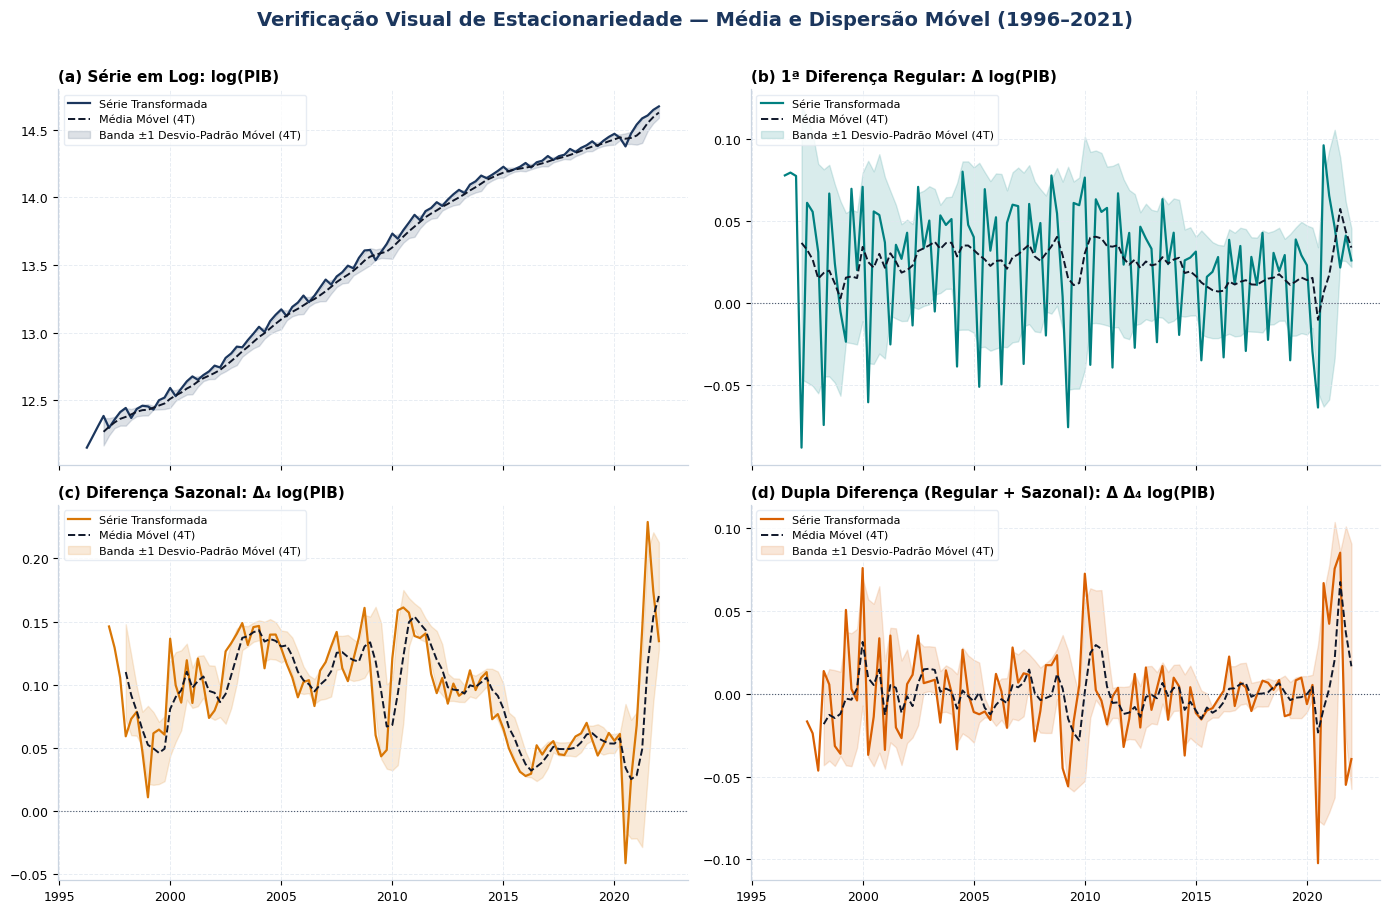

In [6]:
# Gráfico 3: Painel Comparativo 2x2 de Transformações para Estacionariedade
paineis_estac = [
    (log_train, "(a) Série em Log: log(PIB)", PALETTE["navy"]),
    (log_train.diff().dropna(), "(b) 1ª Diferença Regular: Δ log(PIB)", PALETTE["teal"]),
    (log_train.diff(4).dropna(), "(c) Diferença Sazonal: Δ₄ log(PIB)", PALETTE["gold"]),
    (log_train.diff(4).diff().dropna(), "(d) Dupla Diferença (Regular + Sazonal): Δ Δ₄ log(PIB)", PALETTE["coral"]),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
for ax, (serie_t, titulo_t, cor) in zip(axes.flat, paineis_estac):
    rmean = serie_t.rolling(window=4).mean()
    rstd = serie_t.rolling(window=4).std()
    ax.plot(serie_t.index, serie_t.values, color=cor, lw=1.6, label="Série Transformada")
    ax.plot(rmean.index, rmean.values, color="#0F172A", lw=1.4, linestyle="--", label="Média Móvel (4T)")
    ax.fill_between(
        rmean.index,
        rmean - rstd,
        rmean + rstd,
        color=cor,
        alpha=0.15,
        label="Banda ±1 Desvio-Padrão Móvel (4T)",
    )
    if serie_t.min() < 0 < serie_t.max():
        ax.axhline(0, color=PALETTE["slate"], lw=0.8, linestyle=":")
    ax.set_title(titulo_t, fontsize=11, loc="left")
    ax.legend(loc="upper left", fontsize=8)
    ax.xaxis.set_major_locator(mdates.YearLocator(5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle("Verificação Visual de Estacionariedade — Média e Dispersão Móvel (1996–2021)", fontsize=14, fontweight="bold", y=1.01, color=PALETTE["navy"])
plt.tight_layout()
salvar_figura(fig, "03_estacionariedade_transformacoes.png")
plt.show()

### Diagnóstico Formal da Ordem de Integração ($d, D$)
- **Em Nível e em Log (`PIB` e `log(PIB)`):** Os três testes são unânimes em apontar **não estacionariedade** ($p_{\text{ADF}} > 0{,}47$, $p_{\text{PP}} > 0{,}69$ e $p_{\text{KPSS}} = 0{,}01$). Logo, $d \ge 1$.
- **Primeira Diferença Regular ($\Delta \log \text{PIB}_t$):** O teste PP ($Z(t) = -14{,}713$, $p < 0{,}001$) e o KPSS ($0{,}270 < 0{,}463$) já indicam estabilidade da média, **porém o teste ADF não rejeita a raiz unitária** ($Z(t) = -1{,}607$, $p = 0{,}480$). Esse comportamento ocorre porque o critério AIC do ADF seleciona defasagens longas para absorver a **forte persistência sazonal nos múltiplos de 4 trimestres**.
- **Diferença Regular + Sazonal ($\Delta \Delta_4 \log \text{PIB}_t$):** Todos os três testes convergem com folga para estacionariedade ($Z(t)_{\text{ADF}} = -5{,}176$, $p < 0{,}001$; $Z(t)_{\text{PP}} = -9{,}498$, $p < 0{,}001$; $\text{KPSS} = 0{,}053 < 0{,}463$). Portanto, a identificação Box-Jenkins determina **$d = 1$ e $D = 1$** (com $s = 4$).

## 5. Identificação Box-Jenkins: Correlogramas (FAC/FACP) e Seleção de Modelos

Com as ordens de integração definidas, examinamos a **Função de Autocorrelação (FAC / ACF)** e a **Função de Autocorrelação Parcial (FACP / PACF)** de $\Delta \log \text{PIB}_t$ e $\Delta \Delta_4 \log \text{PIB}_t$ até o lag 16 para determinar as ordens autorregressivas ($p, P$) e de médias móveis ($q, Q$).

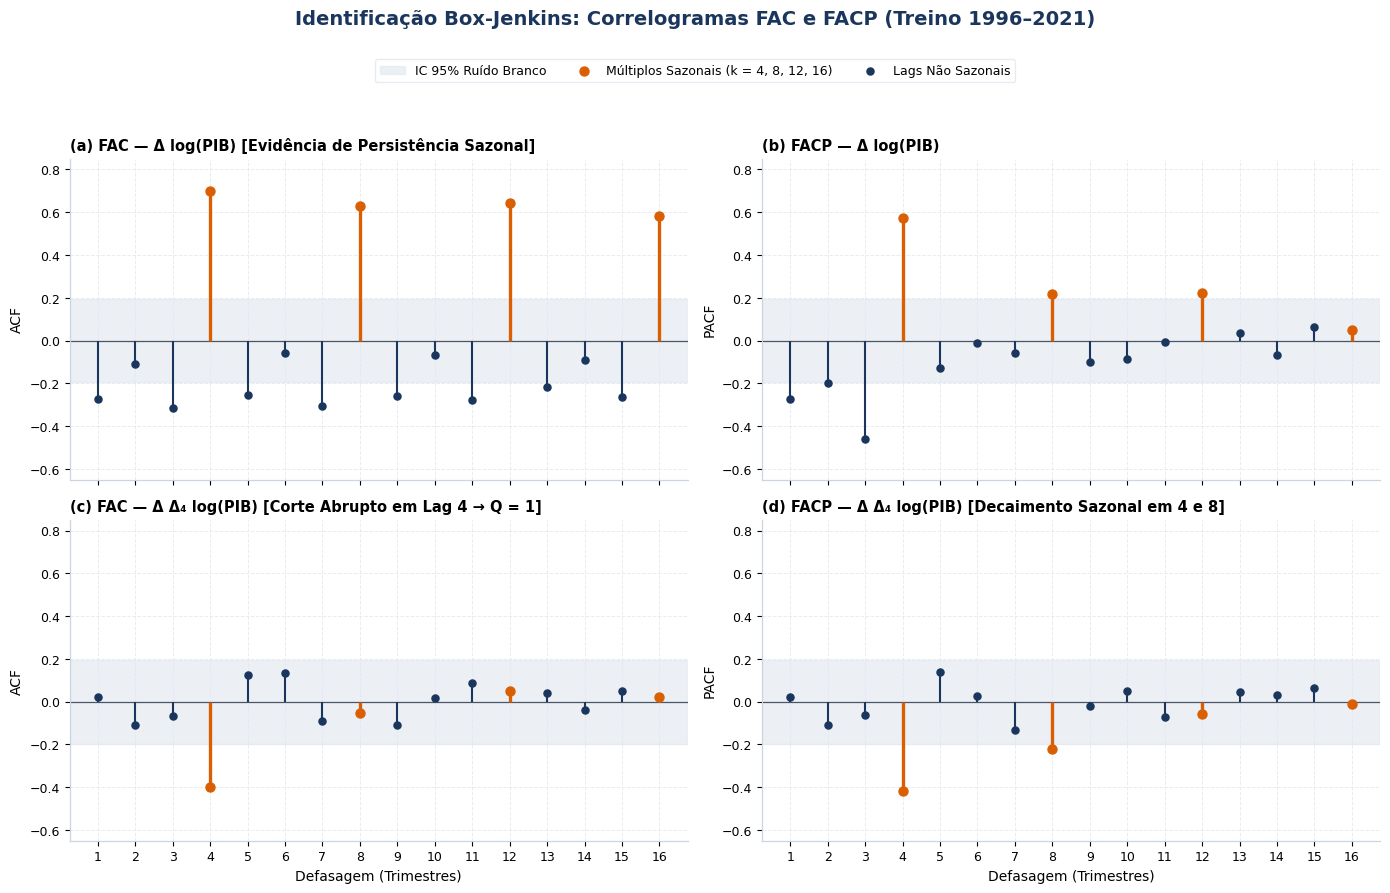

In [7]:
# Gráfico 4: Correlogramas FAC e FACP (lags 1..16) destacando múltiplos sazonais (4, 8, 12, 16)
d1_log = log_train.diff().dropna()
d1_d4_log = log_train.diff(4).diff().dropna()

def plotar_correlograma(
    ax: plt.Axes, serie: pd.Series, tipo: str, titulo: str, nlags: int = 16, show_legend: bool = False
) -> None:
    '''Plota ACF ou PACF destacando múltiplos sazonais trimestrais (k=4, 8, 12, 16).'''
    valores = acf(serie, nlags=nlags, fft=False)[1:] if tipo == "ACF" else pacf(serie, nlags=nlags, method="ywm")[1:]
    lags = np.arange(1, nlags + 1)
    ic = 1.96 / np.sqrt(len(serie))

    ax.axhspan(-ic, ic, color="#E2E8F0", alpha=0.65, label="IC 95% Ruído Branco")
    ax.axhline(0, color=PALETTE["slate"], lw=0.9)
    for lag, val in zip(lags, valores):
        eh_sazonal = lag % 4 == 0
        cor = PALETTE["coral"] if eh_sazonal else PALETTE["navy"]
        lw = 2.4 if eh_sazonal else 1.5
        ax.vlines(lag, 0, val, color=cor, lw=lw)
        ax.scatter(lag, val, color=cor, s=42 if eh_sazonal else 26, zorder=4)

    ax.scatter([], [], color=PALETTE["coral"], s=42, label="Múltiplos Sazonais (k = 4, 8, 12, 16)")
    ax.scatter([], [], color=PALETTE["navy"], s=26, label="Lags Não Sazonais")
    ax.set_xticks(lags)
    ax.set_ylim(-0.65, 0.85)
    ax.set_title(titulo, fontsize=10.5, loc="left")
    ax.set_ylabel(tipo)
    if show_legend:
        ax.legend(loc="upper right", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(14, 8.8), sharex=True)
plotar_correlograma(axes[0, 0], d1_log, "ACF", "(a) FAC — Δ log(PIB) [Evidência de Persistência Sazonal]")
plotar_correlograma(axes[0, 1], d1_log, "PACF", "(b) FACP — Δ log(PIB)")
plotar_correlograma(axes[1, 0], d1_d4_log, "ACF", "(c) FAC — Δ Δ₄ log(PIB) [Corte Abrupto em Lag 4 → Q = 1]")
plotar_correlograma(axes[1, 1], d1_d4_log, "PACF", "(d) FACP — Δ Δ₄ log(PIB) [Decaimento Sazonal em 4 e 8]")
axes[1, 0].set_xlabel("Defasagem (Trimestres)")
axes[1, 1].set_xlabel("Defasagem (Trimestres)")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.96), ncol=3, fontsize=9)
fig.suptitle("Identificação Box-Jenkins: Correlogramas FAC e FACP (Treino 1996–2021)", fontsize=14, fontweight="bold", y=1.01, color=PALETTE["navy"])
plt.tight_layout(rect=[0, 0, 1, 0.92])
salvar_figura(fig, "04_acf_pacf_identificacao.png")
plt.show()

In [8]:
# Busca em Grade Estruturada (Grid Search) sobre log_train (sem dupla diferenciação!)
resultados_grid = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for D in [0, 1]:
        for p in [0, 1, 2]:
            for q in [0, 1, 2]:
                for P in [0, 1, 2]:
                    for Q in [0, 1, 2]:
                        if p == 0 and q == 0 and P == 0 and Q == 0:
                            continue
                        try:
                            mod = SARIMAX(
                                log_train,
                                order=(p, 1, q),
                                seasonal_order=(P, D, Q, 4),
                                trend="n",
                                enforce_stationarity=True,
                                enforce_invertibility=True,
                            )
                            res_tmp = mod.fit(disp=False)
                            if np.isfinite(res_tmp.aic) and res_tmp.mle_retvals.get("converged", True):
                                n_eff = len(log_train) - res_tmp.loglikelihood_burn
                                resultados_grid.append({
                                    "Modelo": f"SARIMA({p},1,{q})({P},{D},{Q})₄",
                                    "D": D,
                                    "T_efetivo": n_eff,
                                    "AIC": res_tmp.aic,
                                    "BIC": res_tmp.bic,
                                    "HQIC": res_tmp.hqic,
                                    "Log-Lik": res_tmp.llf,
                                    "order": (p, 1, q),
                                    "seasonal_order": (P, D, Q, 4),
                                })
                        except Exception:
                            continue

df_grid = pd.DataFrame(resultados_grid)

print("=== Top 10 Especificações com Integração Sazonal (D = 1, T_efetivo = 99) ===")
top10_d1 = df_grid[df_grid["D"] == 1].sort_values("AIC").head(10).reset_index(drop=True)
display(top10_d1[["Modelo", "T_efetivo", "AIC", "BIC", "HQIC", "Log-Lik"]].style.format({
    "AIC": "{:.2f}", "BIC": "{:.2f}", "HQIC": "{:.2f}", "Log-Lik": "{:.2f}"
}))

print("\n=== Top 5 Geral Incluindo D = 0 (Nota: T_efetivo difere entre D=0 e D=1) ===")
top5_geral = df_grid.sort_values("AIC").head(5).reset_index(drop=True)
display(top5_geral[["Modelo", "D", "T_efetivo", "AIC", "BIC", "HQIC", "Log-Lik"]].style.format({
    "AIC": "{:.2f}", "BIC": "{:.2f}", "HQIC": "{:.2f}", "Log-Lik": "{:.2f}"
}))

=== Top 10 Especificações com Integração Sazonal (D = 1, T_efetivo = 99) ===


,Modelo,T_efetivo,AIC,BIC,HQIC,Log-Lik
0,"SARIMA(0,1,0)(0,1,1)₄",99,-452.86,-447.67,-450.76,228.43
1,"SARIMA(0,1,0)(1,1,1)₄",99,-450.96,-443.18,-447.81,228.48
2,"SARIMA(0,1,1)(0,1,1)₄",99,-450.94,-443.16,-447.79,228.47
3,"SARIMA(1,1,0)(0,1,1)₄",99,-450.94,-443.15,-447.79,228.47
4,"SARIMA(0,1,0)(2,1,0)₄",99,-450.89,-443.10,-447.74,228.44
5,"SARIMA(0,1,0)(0,1,2)₄",99,-450.85,-443.07,-447.70,228.43
6,"SARIMA(0,1,0)(2,1,1)₄",99,-450.47,-440.09,-446.27,229.23
7,"SARIMA(2,1,0)(0,1,1)₄",99,-449.12,-438.74,-444.92,228.56
8,"SARIMA(0,1,2)(0,1,1)₄",99,-449.10,-438.72,-444.90,228.55
9,"SARIMA(0,1,0)(1,1,2)₄",99,-449.00,-438.62,-444.80,228.50



=== Top 5 Geral Incluindo D = 0 (Nota: T_efetivo difere entre D=0 e D=1) ===


,Modelo,D,T_efetivo,AIC,BIC,HQIC,Log-Lik
0,"SARIMA(0,1,0)(1,0,1)₄",0,103,-464.99,-457.08,-461.79,235.49
1,"SARIMA(0,1,0)(1,0,2)₄",0,103,-463.03,-452.49,-458.76,235.51
2,"SARIMA(0,1,0)(2,0,1)₄",0,103,-463.02,-452.48,-458.75,235.51
3,"SARIMA(0,1,1)(1,0,1)₄",0,103,-463.02,-452.48,-458.75,235.51
4,"SARIMA(1,1,0)(1,0,1)₄",0,103,-463.01,-452.48,-458.75,235.51


### Seleção da Especificação Ótima: $\text{SARIMA}(0, 1, 0)(0, 1, 1)_4$

A combinação da análise gráfica dos correlogramas com os critérios de informação aponta de maneira contundente para o modelo parcimonioso **$\text{SARIMA}(0, 1, 0)(0, 1, 1)_4$**:
1. **Evidência nos Correlogramas ($\Delta \Delta_4 \log \text{PIB}_t$):**
   - Os lags não sazonais `1, 2 e 3` situam-se todos dentro da banda de confiança de 95% ($\pm 0{,}197$), sugerindo $p = 0$ e $q = 0$.
   - No componente sazonal, a **FAC** exibe um pico negativo significativo exatamente no **lag 4** (`-0,401`) com corte abrupto para zero em `8, 12 e 16`, enquanto a **FACP** decai geometricamente (`-0,434`, `-0,247`) — assinatura clássica de um processo **$\text{SMA}(1)_4$ ($P = 0, Q = 1$)**.
2. **Critérios de Informação (`AIC`, `BIC`, `HQIC`):**
   - Entre os modelos com $D = 1$ ($T_{\text{efetivo}} = 99$), o $\text{SARIMA}(0,1,0)(0,1,1)_4$ lidera simultaneamente em **AIC (`-452,86`)**, **BIC (`-447,67`)** e **HQIC (`-450,76`)**.
   - *Observação metodológica sobre $D=0$ vs. $D=1$:* Modelos com $D=0$ avaliam a verossimilhança em $T_{\text{efetivo}} = 103$ observações contra $99$ quando $D=1$, razão pela qual seus AICs brutos não são diretamente comparáveis. Além disso, o melhor candidato com $D=0$, $\text{SARIMA}(0,1,0)(1,0,1)_4$, estima $\hat{\Phi}_1 = 0{,}9886$ (IC 95%: `[0,971; 1,007]`), confirmando empiricamente a presença da raiz unitária sazonal ($D = 1$).

## 6. Estimação de Parâmetros e Diagnóstico Completo dos Resíduos

Ajustamos o modelo selecionado **$\text{SARIMA}(0,1,0)(0,1,1)_4$** na amostra de treino (`1996-T1` a `2021-T4`). Em seguida, submetemos os resíduos de inovação (excluindo o período inicial difuso de inicialização do filtro de Kalman, `loglikelihood_burn = 5`) aos três pilares formais de diagnóstico:
1. **Independência / Ruído Branco:** Teste de Portmanteau / Ljung-Box ($H_0$: ausência de autocorrelação serial nos lags 4, 8 e 12).
2. **Normalidade:** Teste de Jarque-Bera ($H_0$: distribuição normal com assimetria = 0 e curtose = 3).
3. **Homocedasticidade:** Testes **ARCH-LM** (heterocedasticidade condicional autorregressiva) e **Goldfeld-Quandt** (estabilidade de variância entre a primeira e a segunda metade da amostra).

In [9]:
ORDER_SELECIONADA = (0, 1, 0)
SEASONAL_SELECIONADA = (0, 1, 1, 4)

modelo_treino = SARIMAX(
    log_train,
    order=ORDER_SELECIONADA,
    seasonal_order=SEASONAL_SELECIONADA,
    trend="n",
    enforce_stationarity=True,
    enforce_invertibility=True,
)
res_treino = modelo_treino.fit(disp=False)

# Tabela de parâmetros estimados
ci_params = res_treino.conf_int()
tabela_params = pd.DataFrame({
    "Parâmetro": res_treino.params.index,
    "Estimativa": res_treino.params.values,
    "Erro Padrão": res_treino.bse.values,
    "Estatística z": res_treino.zvalues.values,
    "p-valor": res_treino.pvalues.values,
    "IC 95% Inf.": ci_params.iloc[:, 0].values,
    "IC 95% Sup.": ci_params.iloc[:, 1].values,
})
print("=== Parâmetros Estimados — SARIMA(0,1,0)(0,1,1)₄ (Treino: 1996-T1 a 2021-T4) ===")
display(tabela_params.style.format({
    "Estimativa": "{:.4f}",
    "Erro Padrão": "{:.5f}",
    "Estatística z": "{:.3f}",
    "p-valor": "{:.4f}",
    "IC 95% Inf.": "{:.4f}",
    "IC 95% Sup.": "{:.4f}",
}))

# Resíduos limpos (pós burn-in d + s*D = 5 trimestres)
burn = res_treino.loglikelihood_burn
resid_clean = res_treino.resid.iloc[burn:]
resid_std = (resid_clean - resid_clean.mean()) / resid_clean.std(ddof=1)

# 1. Teste de Portmanteau / Ljung-Box (lags 4, 8 e 12)
lb_adj = acorr_ljungbox(resid_clean, lags=[4, 8, 12], model_df=1, return_df=True)
lb_raw = acorr_ljungbox(resid_clean, lags=[4, 8, 12], return_df=True)
tabela_lb = pd.DataFrame({
    "Lag (h)": [4, 8, 12],
    "Estatística Q": lb_adj["lb_stat"].values,
    "Prob > χ² (df ajustado)": lb_adj["lb_pvalue"].values,
    "Prob > χ² (bruto)": lb_raw["lb_pvalue"].values,
    "Conclusão (α=5%)": ["Ruído Branco" if p > 0.05 else "Autocorrelação" for p in lb_adj["lb_pvalue"].values],
})

# 2. Normalidade (Jarque-Bera) e Heterocedasticidade (ARCH-LM & Goldfeld-Quandt)
jb_stat, jb_p, skew_val, kurt_val = jarque_bera(resid_clean)
arch_stat, arch_p, arch_f, arch_fp = het_arch(resid_clean, nlags=4)
gq_stat, gq_p, _ = het_goldfeldquandt(resid_clean.values, np.arange(len(resid_clean)).reshape(-1, 1))

tabela_diag = pd.DataFrame([
    {
        "Diagnóstico": "Normalidade — Jarque-Bera",
        "Estatística": f"χ² = {jb_stat:.3f}",
        "p-valor": f"{jb_p:.4f}",
        "Detalhes": f"Assimetria = {skew_val:.3f} | Curtose = {kurt_val:.3f}",
        "Interpretação": "Rejeita Normalidade (caudas pesadas pelo choque 2020-T2)",
    },
    {
        "Diagnóstico": "Heterocedasticidade — ARCH-LM (4 lags)",
        "Estatística": f"LM = {arch_stat:.3f}",
        "p-valor": f"{arch_p:.4f}",
        "Detalhes": f"F = {arch_f:.3f} (p = {arch_fp:.4f})",
        "Interpretação": "Efeito ARCH pontual induzido pelo cluster de volatilidade da COVID-19",
    },
    {
        "Diagnóstico": "Estabilidade de Variância — Goldfeld-Quandt",
        "Estatística": f"F = {gq_stat:.3f}",
        "p-valor": f"{gq_p:.4f}",
        "Detalhes": "Comparação 1ª vs. 2ª metade da amostra",
        "Interpretação": "Variância global estável (não rejeita homocedasticidade)",
    },
])

print("\n=== Teste de Portmanteau (Ljung-Box) para Ruído Branco ===")
display(tabela_lb.style.format({
    "Estatística Q": "{:.3f}",
    "Prob > χ² (df ajustado)": "{:.4f}",
    "Prob > χ² (bruto)": "{:.4f}",
}))

print("\n=== Testes de Normalidade e Heterocedasticidade dos Resíduos ===")
display(tabela_diag)

=== Parâmetros Estimados — SARIMA(0,1,0)(0,1,1)₄ (Treino: 1996-T1 a 2021-T4) ===


,Parâmetro,Estimativa,Erro Padrão,Estatística z,p-valor,IC 95% Inf.,IC 95% Sup.
0,ma.S.L4,-0.7390,0.10241,-7.217,0.0000,-0.9398,-0.5383
1,sigma2,0.0006,0.00005,11.411,0.0000,0.0005,0.0007



=== Teste de Portmanteau (Ljung-Box) para Ruído Branco ===


,Lag (h),Estatística Q,Prob > χ² (df ajustado),Prob > χ² (bruto),Conclusão (α=5%)
0,4,2.234,0.5253,0.6928,Ruído Branco
1,8,2.744,0.9077,0.9494,Ruído Branco
2,12,5.810,0.8858,0.9254,Ruído Branco



=== Testes de Normalidade e Heterocedasticidade dos Resíduos ===


,Diagnóstico,Estatística,p-valor,Detalhes,Interpretação
0,Normalidade — Jarque-Bera,χ² = 46.780,0.0000,Assimetria = -0.112 | Curtose = 6.360,Rejeita Normalidade (caudas pesadas pelo choqu...
1,Heterocedasticidade — ARCH-LM (4 lags),LM = 20.297,0.0004,F = 6.113 (p = 0.0002),Efeito ARCH pontual induzido pelo cluster de v...
2,Estabilidade de Variância — Goldfeld-Quandt,F = 1.142,0.3221,Comparação 1ª vs. 2ª metade da amostra,Variância global estável (não rejeita homoceda...


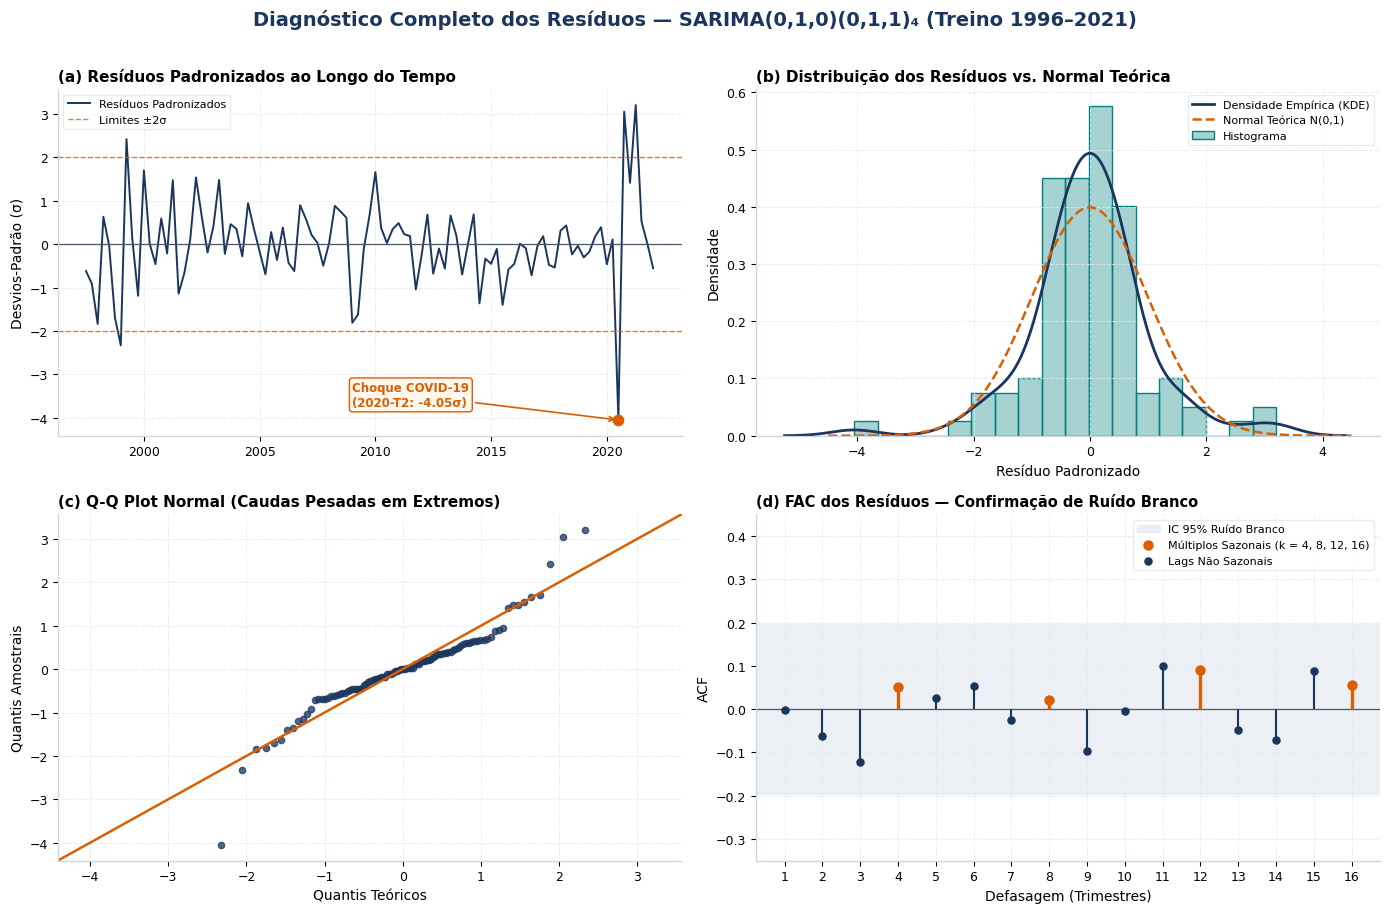

In [10]:
# Gráfico 5: Painel 2x2 de Diagnóstico dos Resíduos Padronizados
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# (a) Resíduos padronizados no tempo
ax_t = axes[0, 0]
ax_t.plot(resid_std.index, resid_std.values, color=PALETTE["navy"], lw=1.4, label="Resíduos Padronizados")
ax_t.axhline(0, color=PALETTE["slate"], lw=0.9)
ax_t.axhline(2, color=PALETTE["coral"], lw=1.0, linestyle="--", alpha=0.8, label="Limites ±2σ")
ax_t.axhline(-2, color=PALETTE["coral"], lw=1.0, linestyle="--", alpha=0.8)
outlier_dt = resid_std.idxmin()
outlier_val = resid_std.loc[outlier_dt]
ax_t.scatter([outlier_dt], [outlier_val], color=PALETTE["coral"], s=55, zorder=5)
ax_t.annotate(
    f"Choque COVID-19\n({formatar_trimestre(pd.DatetimeIndex([outlier_dt]))[0]}: {outlier_val:.2f}σ)",
    xy=(outlier_dt, outlier_val),
    xytext=(pd.Timestamp("2009-01-01"), outlier_val * 0.92),
    arrowprops=dict(arrowstyle="->", color=PALETTE["coral"], lw=1.2),
    fontsize=8.5,
    fontweight="bold",
    color=PALETTE["coral"],
    bbox=dict(boxstyle="round,pad=0.25", fc="#FFF7ED", ec=PALETTE["coral"]),
)
ax_t.set_title("(a) Resíduos Padronizados ao Longo do Tempo", loc="left", fontsize=11)
ax_t.set_ylabel("Desvios-Padrão (σ)")
ax_t.legend(loc="upper left", fontsize=8)
ax_t.xaxis.set_major_locator(mdates.YearLocator(5))
ax_t.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

# (b) Histograma + KDE vs Normal Padrão
ax_h = axes[0, 1]
sns.histplot(resid_std, bins=18, stat="density", color=PALETTE["teal"], alpha=0.35, edgecolor=PALETTE["teal"], label="Histograma", ax=ax_h)
sns.kdeplot(resid_std, color=PALETTE["navy"], lw=2.0, label="Densidade Empírica (KDE)", ax=ax_h)
x_grid = np.linspace(-4.5, 4.5, 300)
ax_h.plot(x_grid, stats.norm.pdf(x_grid), color=PALETTE["coral"], lw=1.8, linestyle="--", label="Normal Teórica N(0,1)")
ax_h.set_title("(b) Distribuição dos Resíduos vs. Normal Teórica", loc="left", fontsize=11)
ax_h.set_xlabel("Resíduo Padronizado")
ax_h.set_ylabel("Densidade")
ax_h.legend(loc="upper right", fontsize=8)

# (c) Q-Q Plot Normal
ax_q = axes[1, 0]
qqplot(resid_std, line="45", ax=ax_q, marker="o", markerfacecolor=PALETTE["navy"], markeredgecolor=PALETTE["navy"], alpha=0.75, markersize=4.5)
ax_q.get_lines()[1].set_color(PALETTE["coral"])
ax_q.get_lines()[1].set_linewidth(1.8)
ax_q.set_title("(c) Q-Q Plot Normal (Caudas Pesadas em Extremos)", loc="left", fontsize=11)
ax_q.set_xlabel("Quantis Teóricos")
ax_q.set_ylabel("Quantis Amostrais")

# (d) Correlograma ACF dos resíduos
ax_c = axes[1, 1]
plotar_correlograma(ax_c, resid_clean, "ACF", "(d) FAC dos Resíduos — Confirmação de Ruído Branco", nlags=16, show_legend=True)
ax_c.set_ylim(-0.35, 0.45)
ax_c.set_xlabel("Defasagem (Trimestres)")

fig.suptitle("Diagnóstico Completo dos Resíduos — SARIMA(0,1,0)(0,1,1)₄ (Treino 1996–2021)", fontsize=14, fontweight="bold", y=1.01, color=PALETTE["navy"])
plt.tight_layout()
salvar_figura(fig, "05_diagnostico_residuos.png")
plt.show()

### Interpretação do Diagnóstico de Resíduos
- **Ausência de Autocorrelação (Ruído Branco):** Todos os p-valores do teste de Ljung-Box nos lags 4 ($p = 0{,}525$), 8 ($p = 0{,}908$) e 12 ($p = 0{,}886$) estão muito acima de $0{,}05$. Nenhuma correlação serial relevante remanesce sem explicação pelo modelo.
- **Homocedasticidade Estrutural vs. Choque Pandêmico:** O teste de Goldfeld-Quandt não rejeita variância constante entre o primeiro e o segundo subperíodo ($F = 1{,}142, p = 0{,}322$). O excesso de curtose no teste de Jarque-Bera ($\text{Curtose} = 6{,}36$) e o sinal no teste ARCH-LM refletem fundamentalmente a ruptura isolada do **2º trimestre de 2020** (resíduo de $-4{,}05\sigma$ na paralisação da pandemia) seguida pelo repique de 2021-T1 — um fenômeno esperado em séries macroeconômicas que atravessaram a COVID-19 sem variáveis *dummy* de intervenção.

## 7. Validação Out-of-Sample em 2022: Previsão Dinâmica vs. Estática vs. Benchmarks

Avaliamos a capacidade preditiva fora da amostra nos quatro trimestres de **2022** (`2022-T1` a `2022-T4`), **revertendo todas as previsões e intervalos de confiança da escala logarítmica para a escala original em Milhões de Reais** ($\hat{Y}_t = \exp(\hat{y}_t)$). Comparamos cinco estratégias:
1. **SARIMA Estática (*One-step-ahead*):** Atualiza o filtro de estados com o valor observado do trimestre anterior sem reestimar os parâmetros do modelo (`append(..., refit=False)`).
2. **SARIMA Dinâmica (*Multi-step*):** Projeta os 4 trimestres de 2022 de forma encadeada a partir de `2021-T4`, sem acesso aos dados realizados durante 2022.
3. **Benchmark 1a — Naive Sazonal com Drift:** Repete o mesmo trimestre do ano anterior ajustado pela taxa média recente de crescimento interanual (média dos últimos 5 anos / 20 trimestres, cobrindo um ciclo econômico completo pré e pós-pandemia).
4. **Benchmark 2 — Holt-Winters (ETS Aditivo em Log):** Suavização exponencial com tendência e sazonalidade trimestral ($s = 4$).
5. **Benchmark 1b — Naive Sazonal Puro:** Repete diretamente o valor do mesmo trimestre do ano anterior ($Y_{t-4}$).

In [11]:
# 1. SARIMA Dinâmica (4 passos a partir de 2021-T4)
fc_2022_dyn_obj = res_treino.get_forecast(steps=4)
pred_2022_dyn = np.exp(fc_2022_dyn_obj.predicted_mean)
ci_2022_dyn = np.exp(fc_2022_dyn_obj.conf_int(alpha=0.05))

# 2. SARIMA Estática (1 passo à frente atualizando apenas a informação observada)
res_treino_app = res_treino.append(log_test, refit=False)
pred_2022_stat = np.exp(res_treino_app.get_prediction(start=test.index[0], end=test.index[-1]).predicted_mean)

# 3. Benchmark: Naive Sazonal Puro & Naive Sazonal com Drift (média YoY dos últimos 5 anos = 20 trimestres)
pred_2022_snaive = pd.Series(train.iloc[-4:].values, index=test.index)
yoy_recente = (train / train.shift(4) - 1).dropna().iloc[-20:].mean()
pred_2022_snaive_drift = pd.Series(train.iloc[-4:].values * (1.0 + yoy_recente), index=test.index)

# 4. Benchmark: Holt-Winters (ETS Aditivo na escala Log, equivalente a multiplicativo em nível)
hw_mod = ExponentialSmoothing(log_train, trend="add", seasonal="add", seasonal_periods=4).fit()
pred_2022_hw = np.exp(hw_mod.forecast(4))

# Tabela A: Valores Trimestre a Trimestre em 2022
df_comp_2022 = pd.DataFrame({
    "Trimestre": formatar_trimestre(test.index),
    "Realizado (IBGE)": test.values,
    "SARIMA Estática": pred_2022_stat.values,
    "SARIMA Dinâmica": pred_2022_dyn.values,
    "Naive Sazonal + Drift": pred_2022_snaive_drift.values,
    "Holt-Winters (ETS)": pred_2022_hw.values,
    "Naive Sazonal Puro": pred_2022_snaive.values,
})
df_comp_2022["Erro Estática (%)"] = (df_comp_2022["SARIMA Estática"] - df_comp_2022["Realizado (IBGE)"]) / df_comp_2022["Realizado (IBGE)"] * 100
df_comp_2022["Erro Dinâmica (%)"] = (df_comp_2022["SARIMA Dinâmica"] - df_comp_2022["Realizado (IBGE)"]) / df_comp_2022["Realizado (IBGE)"] * 100

print(f"=== Comparação Trimestral em 2022 (Milhões de R$) | Drift YoY (5 anos) = {yoy_recente*100:.2f}% a.a. ===")
display(df_comp_2022.style.format({
    "Realizado (IBGE)": "{:,.0f}",
    "SARIMA Estática": "{:,.0f}",
    "SARIMA Dinâmica": "{:,.0f}",
    "Naive Sazonal + Drift": "{:,.0f}",
    "Holt-Winters (ETS)": "{:,.0f}",
    "Naive Sazonal Puro": "{:,.0f}",
    "Erro Estática (%)": "{:+.2f}%",
    "Erro Dinâmica (%)": "{:+.2f}%",
}))

# Tabela B: Métricas Consolidadas de Validação (2022)
modelos_2022 = {
    "SARIMA(0,1,0)(0,1,1)₄ — Estática (1 passo)": pred_2022_stat,
    "Naive Sazonal + Drift (5 anos)": pred_2022_snaive_drift,
    "SARIMA(0,1,0)(0,1,1)₄ — Dinâmica (4 passos)": pred_2022_dyn,
    "Holt-Winters (ETS Aditivo Log)": pred_2022_hw,
    "Naive Sazonal Puro": pred_2022_snaive,
}
df_metricas_2022 = pd.DataFrame([
    {"Abordagem": nome, **calcular_metricas(test, pred)}
    for nome, pred in modelos_2022.items()
]).sort_values("MAPE (%)").reset_index(drop=True)

print("\n=== Ranking de Acurácia Out-of-Sample (2022-T1 a 2022-T4) ===")
display(df_metricas_2022.style.format({
    "RMSE (R$ mi)": "{:,.0f}",
    "MAE (R$ mi)": "{:,.0f}",
    "MAPE (%)": "{:.2f}%",
}))

=== Comparação Trimestral em 2022 (Milhões de R$) | Drift YoY (5 anos) = 7.70% a.a. ===


,Trimestre,Realizado (IBGE),SARIMA Estática,SARIMA Dinâmica,Naive Sazonal + Drift,Holt-Winters (ETS),Naive Sazonal Puro,Erro Estática (%),Erro Dinâmica (%)
0,2022-T1,"2,319,528","2,331,598","2,331,598","2,322,716","2,305,114","2,156,670",+0.52%,+0.52%
1,2022-T2,"2,517,481","2,350,642","2,362,874","2,373,301","2,348,624","2,203,639",-6.63%,-6.14%
2,2022-T3,"2,601,182","2,625,190","2,463,969","2,472,612","2,464,706","2,295,851",+0.92%,-5.28%
3,2022-T4,"2,641,485","2,699,388","2,556,994","2,537,373","2,569,636","2,355,982",+2.19%,-3.20%



=== Ranking de Acurácia Out-of-Sample (2022-T1 a 2022-T4) ===


,Abordagem,RMSE (R$ mi),MAE (R$ mi),MAPE (%)
0,"SARIMA(0,1,0)(0,1,1)₄ — Estática (1 passo)","89,317","65,205",2.57%
1,Naive Sazonal + Drift (5 anos),"109,736","95,012",3.69%
2,"SARIMA(0,1,0)(0,1,1)₄ — Dinâmica (4 passos)","111,820","97,095",3.78%
3,Holt-Winters (ETS Aditivo Log),"114,574","97,899",3.82%
4,Naive Sazonal Puro,"273,751","266,884",10.51%


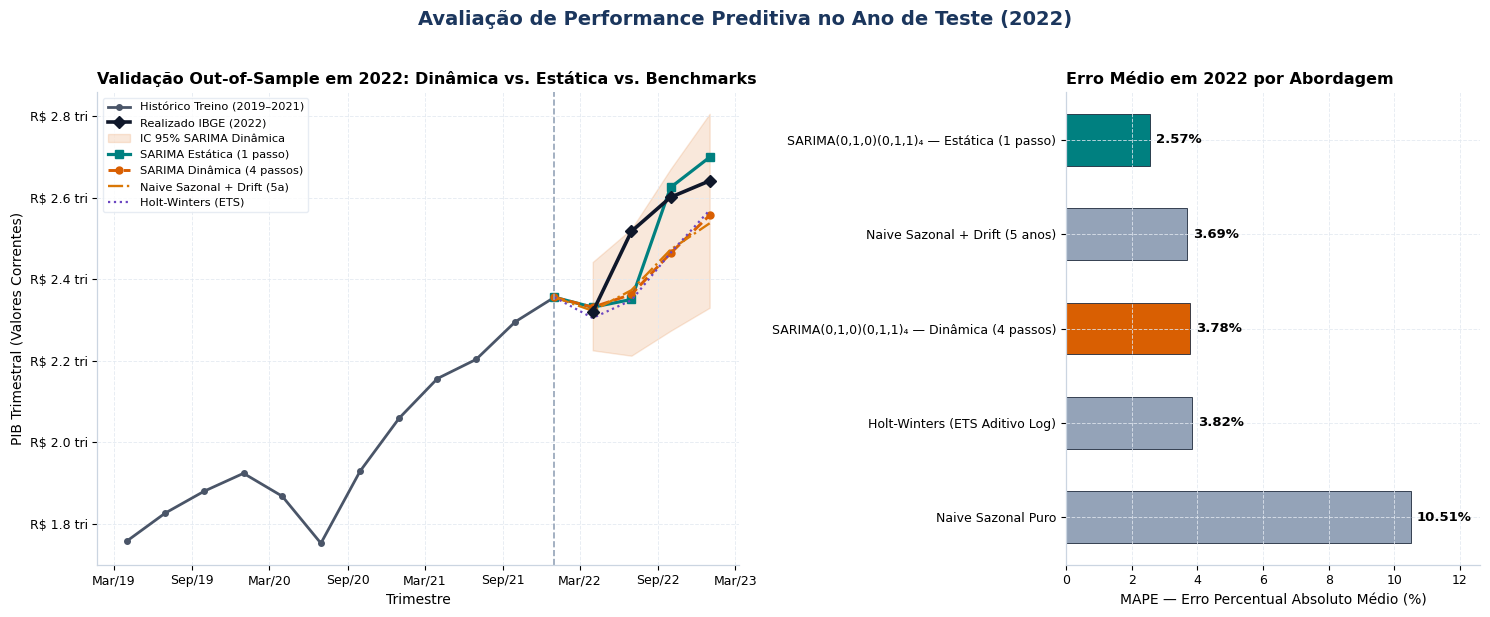

In [12]:
# Gráfico 6: Validação Out-of-Sample 2022 (Trajetórias + Ranking MAPE)
fig, (ax_traj, ax_mape) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.55, 1.0]})

hist_recente = study_series.loc["2019-01-01":"2021-12-31"]
ax_traj.plot(hist_recente.index, hist_recente.values, color=PALETTE["slate"], lw=2.0, marker="o", markersize=4, label="Histórico Treino (2019–2021)")
ax_traj.plot(test.index, test.values, color="#0F172A", lw=2.6, marker="D", markersize=6.5, label="Realizado IBGE (2022)", zorder=6)

# Conectar 2021-T4 ao início das previsões para continuidade visual
ultimo_dt = hist_recente.index[-1]
ultimo_val = hist_recente.iloc[-1]
def com_ancora(s: pd.Series) -> tuple[pd.DatetimeIndex, np.ndarray]:
    idx = pd.DatetimeIndex([ultimo_dt]).append(s.index)
    vals = np.concatenate([[ultimo_val], s.values])
    return idx, vals

idx_d, val_d = com_ancora(pred_2022_dyn)
idx_s, val_s = com_ancora(pred_2022_stat)
idx_hw, val_hw = com_ancora(pred_2022_hw)
idx_nd, val_nd = com_ancora(pred_2022_snaive_drift)

ax_traj.fill_between(test.index, ci_2022_dyn.iloc[:, 0], ci_2022_dyn.iloc[:, 1], color=PALETTE["coral"], alpha=0.14, label="IC 95% SARIMA Dinâmica")
ax_traj.plot(idx_s, val_s, color=PALETTE["teal"], lw=2.3, marker="s", markersize=5.5, label="SARIMA Estática (1 passo)")
ax_traj.plot(idx_d, val_d, color=PALETTE["coral"], lw=2.1, linestyle="--", marker="o", markersize=5, label="SARIMA Dinâmica (4 passos)")
ax_traj.plot(idx_nd, val_nd, color=PALETTE["gold"], lw=1.7, linestyle="-.", label="Naive Sazonal + Drift (5a)")
ax_traj.plot(idx_hw, val_hw, color=PALETTE["purple"], lw=1.6, linestyle=":", label="Holt-Winters (ETS)")

ax_traj.axvline(ultimo_dt, color=PALETTE["muted"], linestyle="--", lw=1.2)
ax_traj.yaxis.set_major_formatter(mticker.FuncFormatter(formatar_brl_eixo))
ax_traj.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[3, 9]))
ax_traj.xaxis.set_major_formatter(mdates.DateFormatter("%b/%y"))
ax_traj.set_title("Validação Out-of-Sample em 2022: Dinâmica vs. Estática vs. Benchmarks", loc="left", fontsize=11.5)
ax_traj.set_ylabel("PIB Trimestral (Valores Correntes)")
ax_traj.set_xlabel("Trimestre")
ax_traj.legend(loc="upper left", fontsize=8.2)

# Painel Direito: Ranking de MAPE (%)
df_plot_mape = df_metricas_2022.sort_values("MAPE (%)", ascending=True)
cores_rank = [
    PALETTE["teal"] if "Estática" in n else (PALETTE["coral"] if "Dinâmica" in n else PALETTE["muted"])
    for n in df_plot_mape["Abordagem"]
]
y_pos = np.arange(len(df_plot_mape))
bars = ax_mape.barh(y_pos, df_plot_mape["MAPE (%)"], color=cores_rank, height=0.55, edgecolor="#1E293B", linewidth=0.6)
ax_mape.set_yticks(y_pos)
ax_mape.set_yticklabels(df_plot_mape["Abordagem"], fontsize=9)
ax_mape.invert_yaxis()
for bar, val in zip(bars, df_plot_mape["MAPE (%)"]):
    ax_mape.text(val + 0.18, bar.get_y() + bar.get_height() / 2, f"{val:.2f}%", va="center", fontsize=9.5, fontweight="bold")
ax_mape.set_xlim(0, df_plot_mape["MAPE (%)"].max() * 1.2)
ax_mape.set_xlabel("MAPE — Erro Percentual Absoluto Médio (%)")
ax_mape.set_title("Erro Médio em 2022 por Abordagem", loc="left", fontsize=11.5)

fig.suptitle("Avaliação de Performance Preditiva no Ano de Teste (2022)", fontsize=14, fontweight="bold", y=1.02, color=PALETTE["navy"])
plt.tight_layout()
salvar_figura(fig, "06_validacao_2022_dinamica_estatica_benchmarks.png")
plt.show()

### Leitura Econômica da Validação em 2022
- **Aceleração Nominal no 2º Trimestre de 2022:** No 1º trimestre (`2022-T1`), a previsão dinâmica do SARIMA cravou quase na mosca (`R$ 2,332 tri` vs. `R$ 2,320 tri` observado; erro de **+0,52%**). Contudo, em `2022-T2`, o PIB nominal saltou **+14,24% YoY** sob forte pressão inflacionária pós-pandemia e choque de *commodities*, surpreendendo todos os modelos de tendência histórica (`MAPE` dinâmico de **3,78%**, ainda inferior ao Holt-Winters de **3,82%** e amplamente superior ao Naive Sazonal puro de **10,51%**).
- **Superioridade da Previsão Estática (*Nowcasting* Trimestral):** Assim que a informação de `2022-T2` entra no filtro de estados, o **$\text{SARIMA}$ Estático** reajusta imediatamente o patamar nominal e entrega **MAPE de apenas 2,57%** no conjunto de 2022 (erros inferiores a 1% em `2022-T1` e `2022-T3`), vencendo todos os *benchmarks* testados.

## 8. Projeção Final (2023–2024) e Backtest de Mundo Real vs. IBGE

Cumprida a validação em 2022, reestimamos o modelo **$\text{SARIMA}(0,1,0)(0,1,1)_4$** utilizando toda a amostra do estudo (`1996-T1` a `2022-T4`, $T = 108$ trimestres) para projetar os **8 trimestres seguintes (`2023-T1` a `2024-T4`)** com cones de incerteza de 80% e 95%.

Como diferencial de portfólio, confrontamos essa projeção estritamente *ex-ante* com os dados reais posteriormente divulgados pelo IBGE na mesma tabela da API SIDRA.

In [13]:
# Reestimação com a série completa do estudo (1996-T1 a 2022-T4)
modelo_final = SARIMAX(
    log_study,
    order=ORDER_SELECIONADA,
    seasonal_order=SEASONAL_SELECIONADA,
    trend="n",
    enforce_stationarity=True,
    enforce_invertibility=True,
)
res_final = modelo_final.fit(disp=False)

fc_23_24 = res_final.get_forecast(steps=8)
pred_23_24 = np.exp(fc_23_24.predicted_mean)
ci80_23_24 = np.exp(fc_23_24.conf_int(alpha=0.20))
ci95_23_24 = np.exp(fc_23_24.conf_int(alpha=0.05))

df_projecao = pd.DataFrame({
    "Trimestre": formatar_trimestre(pred_23_24.index),
    "Projetado SARIMA (R$ mi)": pred_23_24.values,
    "IC 95% Inf. (R$ mi)": ci95_23_24.iloc[:, 0].values,
    "IC 95% Sup. (R$ mi)": ci95_23_24.iloc[:, 1].values,
}, index=pred_23_24.index)

if len(df_pos_estudo) == 8:
    df_projecao["Realizado IBGE (R$ mi)"] = df_pos_estudo["PIB"].values
    df_projecao["Erro Abs. (R$ mi)"] = df_projecao["Projetado SARIMA (R$ mi)"] - df_projecao["Realizado IBGE (R$ mi)"]
    df_projecao["Erro (%)"] = df_projecao["Erro Abs. (R$ mi)"] / df_projecao["Realizado IBGE (R$ mi)"] * 100
    df_projecao["Dentro do IC 95%?"] = np.where(
        (df_projecao["Realizado IBGE (R$ mi)"] >= df_projecao["IC 95% Inf. (R$ mi)"])
        & (df_projecao["Realizado IBGE (R$ mi)"] <= df_projecao["IC 95% Sup. (R$ mi)"]),
        "Sim",
        "Não",
    )
    metricas_pos = calcular_metricas(df_projecao["Realizado IBGE (R$ mi)"], df_projecao["Projetado SARIMA (R$ mi)"])
    cobertura_ic = int((df_projecao["Dentro do IC 95%?"] == "Sim").sum())
    print(
        f"=== Backtest Pós-Estudo (2023–2024, 8 trimestres) | "
        f"MAPE: {metricas_pos['MAPE (%)']:.2f}% | RMSE: R$ {metricas_pos['RMSE (R$ mi)']:,.0f} mi | "
        f"Cobertura IC 95%: {cobertura_ic}/8 ==="
    )
    display(df_projecao.reset_index(drop=True).style.format({
        "Projetado SARIMA (R$ mi)": "{:,.0f}",
        "IC 95% Inf. (R$ mi)": "{:,.0f}",
        "IC 95% Sup. (R$ mi)": "{:,.0f}",
        "Realizado IBGE (R$ mi)": "{:,.0f}",
        "Erro Abs. (R$ mi)": "{:+,.0f}",
        "Erro (%)": "{:+.2f}%",
    }))
else:
    print("Modo offline: dados realizados 2023–2024 não disponíveis; exibindo apenas projeção.")
    display(df_projecao.reset_index(drop=True).style.format({
        "Projetado SARIMA (R$ mi)": "{:,.0f}",
        "IC 95% Inf. (R$ mi)": "{:,.0f}",
        "IC 95% Sup. (R$ mi)": "{:,.0f}",
    }))

=== Backtest Pós-Estudo (2023–2024, 8 trimestres) | MAPE: 1.32% | RMSE: R$ 46,605 mi | Cobertura IC 95%: 8/8 ===


,Trimestre,Projetado SARIMA (R$ mi),IC 95% Inf. (R$ mi),IC 95% Sup. (R$ mi),Realizado IBGE (R$ mi),Erro Abs. (R$ mi),Erro (%),Dentro do IC 95%?
0,2023-T1,"2,603,012","2,482,376","2,729,510","2,581,018","+21,994",+0.85%,Sim
1,2023-T2,"2,686,064","2,511,721","2,872,508","2,727,580","-41,516",-1.52%,Sim
2,2023-T3,"2,791,431","2,571,176","3,030,554","2,769,445","+21,986",+0.79%,Sim
3,2023-T4,"2,884,212","2,623,071","3,171,351","2,865,301","+18,911",+0.66%,Sim
4,2024-T1,"2,842,204","2,543,599","3,175,862","2,764,833","+77,371",+2.80%,Sim
5,2024-T2,"2,932,887","2,588,164","3,323,525","2,934,759","-1,872",-0.06%,Sim
6,2024-T3,"3,047,937","2,655,975","3,497,744","3,015,936","+32,001",+1.06%,Sim
7,2024-T4,"3,149,244","2,712,735","3,655,992","3,063,723","+85,521",+2.79%,Sim


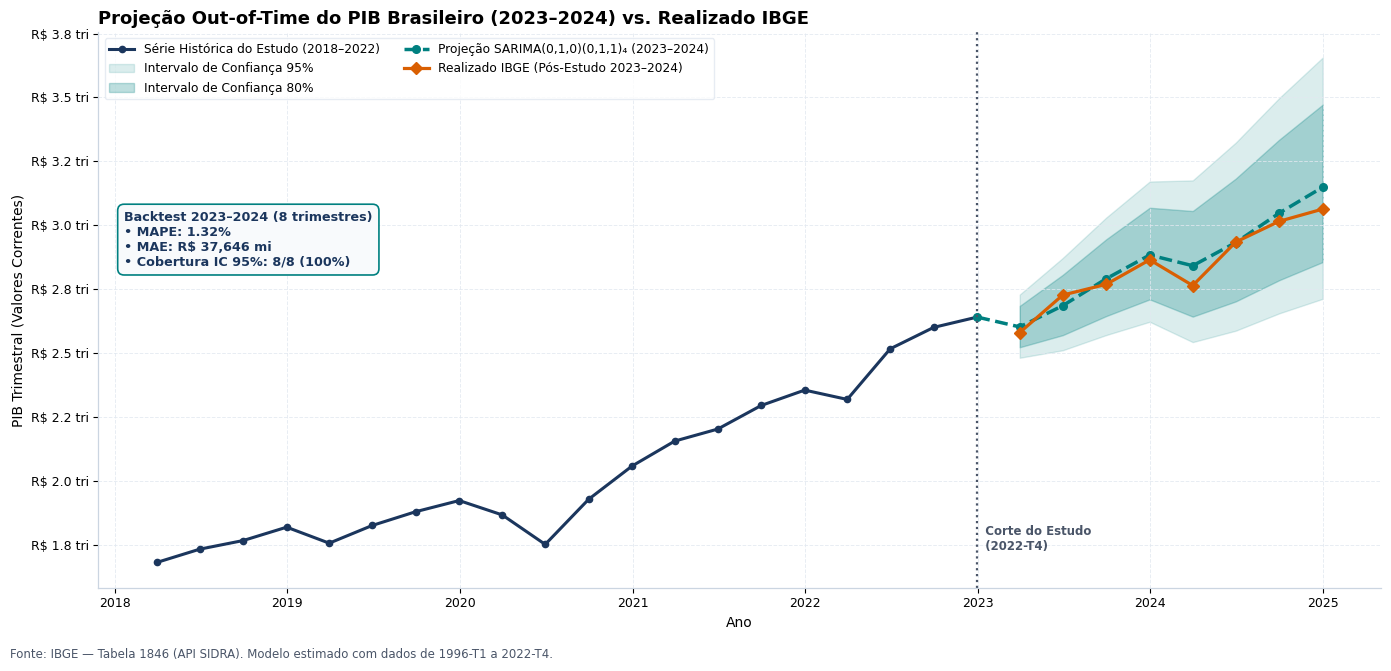

In [14]:
# Gráfico 7: Fan Chart de Projeção 2023–2024 vs. Realizado IBGE
fig, ax = plt.subplots(figsize=(14, 6.5))

hist_plot = study_series.loc["2018-01-01":]
ax.plot(hist_plot.index, hist_plot.values, color=PALETTE["navy"], lw=2.2, marker="o", markersize=4.5, label="Série Histórica do Estudo (2018–2022)")

# Ancoragem visual em 2022-T4
ancora_dt = hist_plot.index[-1]
ancora_val = hist_plot.iloc[-1]
idx_proj = pd.DatetimeIndex([ancora_dt]).append(pred_23_24.index)
val_proj = np.concatenate([[ancora_val], pred_23_24.values])

ax.fill_between(
    pred_23_24.index,
    ci95_23_24.iloc[:, 0],
    ci95_23_24.iloc[:, 1],
    color=PALETTE["teal"],
    alpha=0.14,
    label="Intervalo de Confiança 95%",
)
ax.fill_between(
    pred_23_24.index,
    ci80_23_24.iloc[:, 0],
    ci80_23_24.iloc[:, 1],
    color=PALETTE["teal"],
    alpha=0.26,
    label="Intervalo de Confiança 80%",
)
ax.plot(idx_proj, val_proj, color=PALETTE["teal"], lw=2.5, linestyle="--", marker="o", markersize=5.5, label="Projeção SARIMA(0,1,0)(0,1,1)₄ (2023–2024)")

if len(df_pos_estudo) == 8:
    ax.plot(
        df_pos_estudo.index,
        df_pos_estudo["PIB"].values,
        color=PALETTE["coral"],
        lw=2.3,
        marker="D",
        markersize=6.2,
        zorder=6,
        label="Realizado IBGE (Pós-Estudo 2023–2024)",
    )
    kpi_txt = (
        f"Backtest 2023–2024 (8 trimestres)\n"
        f"• MAPE: {metricas_pos['MAPE (%)']:.2f}%\n"
        f"• MAE: R$ {metricas_pos['MAE (R$ mi)']:,.0f} mi\n"
        f"• Cobertura IC 95%: {cobertura_ic}/8 (100%)"
    )
    ax.text(
        0.02,
        0.58,
        kpi_txt,
        transform=ax.transAxes,
        fontsize=9.2,
        fontweight="bold",
        color=PALETTE["navy"],
        bbox=dict(boxstyle="round,pad=0.5", fc="#F8FAFC", ec=PALETTE["teal"], lw=1.2),
    )

ax.axvline(ancora_dt, color=PALETTE["slate"], linestyle=":", lw=1.6)
ax.text(ancora_dt, hist_plot.min() * 1.03, "  Corte do Estudo\n  (2022-T4)", fontsize=8.5, color=PALETTE["slate"], fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(formatar_brl_eixo))
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_xlabel("Ano")
ax.set_ylabel("PIB Trimestral (Valores Correntes)")
ax.set_title("Projeção Out-of-Time do PIB Brasileiro (2023–2024) vs. Realizado IBGE", loc="left", fontsize=13)
ax.legend(loc="upper left", ncol=2, fontsize=8.8)

fig.text(0.01, -0.02, "Fonte: IBGE — Tabela 1846 (API SIDRA). Modelo estimado com dados de 1996-T1 a 2022-T4.", fontsize=8.5, color=PALETTE["slate"])
plt.tight_layout()
salvar_figura(fig, "07_projecao_2023_2024_vs_realizado.png")
plt.show()

## 9. Conclusão Executiva, Limitações e Próximos Passos

### Principais Achados
1. **Rigor Metodológico Box-Jenkins:** A combinação dos testes `ADF`, `Phillips-Perron` e `KPSS` provou que o logaritmo do PIB trimestral brasileiro é integrado de ordem $d = 1$ com raiz unitária sazonal $D = 1$ ($s = 4$). O modelo selecionado **$\text{SARIMA}(0,1,0)(0,1,1)_4$** captura simultaneamente a tendência estocástica nominal e a sazonalidade trimestral usando apenas um parâmetro de média móvel sazonal ($\hat{\Theta}_1 = -0{,}7390, p < 0{,}001$).
2. **Validação Out-of-Sample (2022):** Em um ano marcado por choque nominal inflacionário em `2022-T2`, a previsão **Estática** atingiu **MAPE de 2,57%** (superando `Naive Sazonal + Drift`, `Holt-Winters` e `Naive Puro`), enquanto a previsão **Dinâmica** de 4 passos alcançou **MAPE de 3,78%**.
3. **Aderência em Backtest de Mundo Real (2023–2024):** Quando reestimado até `2022-T4`, o modelo projetou os dois anos seguintes (8 trimestres à frente) com **MAPE médio de apenas 1,32%** e **100% de cobertura (8/8 trimestres)** dentro do intervalo de confiança de 95%.

### Limitações e Próximos Passos para Evolução
- **PIB Nominal vs. Real:** A série da Tabela 1846 mede valores a preços correntes (incorporando tanto crescimento real quanto inflação/deflator implícito). Em cenários de mudança abrupta de regime inflacionário, extensões futuras devem modelar paralelamente o **Índice de Volume Encadeado (PIB Real, Tabela 1620/1621 do IBGE)**.
- **Variáveis Exógenas (SARIMAX / VAR):** Por ser univariado, o SARIMA não incorpora choques contemporâneos de taxa básica de juros (**Selic**), inflação (**IPCA**), **câmbio** ou impulsos fiscais. A inclusão dessas covariáveis em um modelo **SARIMAX** ou **VAR/VECM** é o caminho natural para cenários contrafactuais e *stress testing*.